> **Colab-версия.** Первая ячейка распаковывает проект (код пакета `lab01`, данные AqSolDB, тесты) в рабочую папку, поэтому ничего загружать отдельно не нужно. Запусти её первой, затем *Runtime → Run all*. Для сдачи используется `lab01.ipynb`, а не этот файл.

In [ ]:
#@title Распаковка проекта (запусти эту ячейку первой; код внутри скрыт)
import base64, io, os, sys, zipfile
if not os.path.exists("src/lab01"):
    _B64 = "..."
    zipfile.ZipFile(io.BytesIO(base64.b64decode(_B64))).extractall("lab01")
    os.chdir("lab01")
    try:
        import pytest  # noqa: F401
    except ImportError:
        import subprocess
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pytest"], check=False)
sys.path.insert(0, os.getcwd())
print("Рабочая папка:", os.getcwd(), "| файлов проекта:", sum(len(f) for _, _, f in os.walk(".")))


Рабочая папка: /content/lab01 | файлов проекта: 20


<a id="lab01"></a>

# Lab01 - sprint 1

**Датасет:** AqSolDB (OpenML id 43546), Sorkun M. C., Khetan A., Er S. *AqSolDB, a curated reference set of aqueous
solubility and 2D descriptors for a diverse set of compounds* // Scientific Data, 2019, 6:143.
doi:10.1038/s41597-019-0151-1

**Авторы:** ✍️ ФИО (и напарник, если работаете вдвоём)

**Три случайные величины:** растворимость в воде LogS, липофильность Mol LogP, молекулярная масса Mol Wt.

> **Как читать этот документ.** Блоки «✍️ ЗАПОЛНИ САМА» — это места, где нужен твой собственный текст
> (интерпретации, математика, выводы). Весь код спрятан тегом `remove-input`; при экспорте в HTML
> (`export_html.sh`) он не показывается, в самом ноутбуке его можно раскрыть.

<a id="toc"></a>

## Оглавление

**Спринт 1**

- [0. Датасет и подготовка](#data)
- [1. Random Variable 01 — растворимость в воде (LogS)](#rv1)
  - [1.1 Description](#rv1-desc)
  - [1.2 EDA & Distribution](#rv1-eda)
  - [1.3 Independence & Estimations](#rv1-ind)
  - [1.4 Hypothesis](#rv1-hyp)
  - [1.5 Вывод по величине 01](#rv1-res)
- [2. Random Variable 02 — липофильность (Mol LogP)](#rv2)
  - [2.1 Description](#rv2-desc)
  - [2.2 EDA & Distribution](#rv2-eda)
  - [2.3 Independence & Estimations](#rv2-ind)
  - [2.4 Hypothesis](#rv2-hyp)
  - [2.5 Вывод по величине 02](#rv2-res)
- [3. Random Variable 03 — молекулярная масса (Mol Wt)](#rv3)
  - [3.1 Description](#rv3-desc)
  - [3.2 EDA & Distribution](#rv3-eda)
  - [3.3 Independence & Estimations](#rv3-ind)
  - [3.4 Hypothesis](#rv3-hyp)
  - [3.5 Вывод по величине 03](#rv3-res)
- [4. Lab resume](#resume)
  - [4.1 cat_mark_table](#mark-table)
- [5. Список литературы](#refs)

**Спринт 2**

- [6. Базовые датчики U(0,1)](#base)
- [7. random 01 — LogS](#r1)
  - [7.1 Description](#r1-desc) · [7.2 math desc](#r1-math) · [7.3 code](#r1-code) · [7.4 tests](#r1-tests) · [7.5 resume](#r1-res)
- [8. random 02 — Mol LogP](#r2)
  - [8.1 Description](#r2-desc) · [8.2 math desc](#r2-math) · [8.3 code](#r2-code) · [8.4 tests](#r2-tests) · [8.5 resume](#r2-res)
- [9. random 03 — Mol Wt](#r3)
  - [9.1 Description](#r3-desc) · [9.2 math desc](#r3-math) · [9.3 code](#r3-code) · [9.4 tests](#r3-tests) · [9.5 resume](#r3-res)
- [10. Lab resume](#s2-resume)
  - [10.1 cat_mark_table](#s2-mark-table)
- [11. Список литературы](#s2-refs)

<a id="data"></a>

## 0. Датасет и подготовка

[↑ к оглавлению](#toc)

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown

import lab01_utils as lu

lu.set_style()
pd.options.display.float_format = "{:.4g}".format
pd.options.display.max_columns = 40

df = lu.load_data()          # data/aqsoldb.csv или скачивание с OpenML (id 43546)
cols = lu.detect_columns(df)  # реальные имена нужных колонок

need = {"logS": "растворимость (Solubility)", "logP": "Mol LogP", "molwt": "молекулярная масса (Mol Wt)"}
missing = [v for k, v in need.items() if cols[k] is None]
assert not missing, (
    f"Не нашла колонки: {missing}. Колонки датасета: {list(df.columns)}. "
    "Впиши имена вручную в словарь cols (например cols['logS'] = '...')."
)

x1 = lu.series(df, cols["logS"])
x2 = lu.series(df, cols["logP"])
x3 = lu.series(df, cols["molwt"])
LAB1, UNIT1 = "LogS, log₁₀(моль/л)", "log₁₀(моль/л)"
LAB2, UNIT2 = "Mol LogP, безразмерная", "безразм."
LAB3, UNIT3 = "Mol Wt, г/моль", "г/моль"
C1, C2, C3 = lu.COLORS["rv1"], lu.COLORS["rv2"], lu.COLORS["rv3"]

display(Markdown(f"**Размер датасета:** {df.shape[0]} строк × {df.shape[1]} колонок. "
                 f"Найденные колонки: `{ {k: v for k, v in cols.items() if v} }`"))
display(df.head())

**Размер датасета:** 9982 строк × 26 колонок. Найденные колонки: `{'logS': 'Solubility', 'logP': 'MolLogP', 'molwt': 'MolWt', 'sd': 'SD', 'occ': 'Occurrences', 'group': 'Group', 'arom': 'NumAromaticRings', 'rings': 'RingCount', 'heavy': 'HeavyAtomCount', 'tpsa': 'TPSA'}`

,ID,Name,InChI,InChIKey,SMILES,Solubility,SD,Occurrences,Group,MolWt,MolLogP,MolMR,HeavyAtomCount,NumHAcceptors,NumHDonors,NumHeteroatoms,NumRotatableBonds,NumValenceElectrons,NumAromaticRings,NumSaturatedRings,NumAliphaticRings,RingCount,TPSA,LabuteASA,BalabanJ,BertzCT
0,A-3,"N,N,N-trimethyloctadecan-1-aminium bromide",InChI=1S/C21H46N.BrH/c1-5-6-7-8-9-10-11-12-13-...,SZEMGTQCPRNXEG-UHFFFAOYSA-M,[Br-].CCCCCCCCCCCCCCCCCC[N+](C)(C)C,-3.616,0,1,G1,392.5,3.958,102.4,23,0,0,2,17,142,0,0,0,0,0,158.5,0,210.4
1,A-4,Benzo[cd]indol-2(1H)-one,InChI=1S/C11H7NO/c13-11-8-5-1-3-7-4-2-6-9(12-1...,GPYLCFQEKPUWLD-UHFFFAOYSA-N,O=C1Nc2cccc3cccc1c23,-3.255,0,1,G1,169.2,2.406,51.9,13,1,1,2,0,62,2,0,1,3,29.1,75.18,2.583,511.2
2,A-5,4-chlorobenzaldehyde,InChI=1S/C7H5ClO/c8-7-3-1-6(5-9)2-4-7/h1-5H,AVPYQKSLYISFPO-UHFFFAOYSA-N,Clc1ccc(C=O)cc1,-2.177,0,1,G1,140.6,2.152,36.84,9,1,0,2,1,46,1,0,0,1,17.07,58.26,3.01,202.7
3,A-8,"zinc bis[2-hydroxy-3,5-bis(1-phenylethyl)benzo...",InChI=1S/2C23H22O3.Zn/c2*1-15(17-9-5-3-6-10-17...,XTUPUYCJWKHGSW-UHFFFAOYSA-L,[Zn++].CC(c1ccccc1)c2cc(C(C)c3ccccc3)c(O)c(c2)...,-3.924,0,1,G1,756.2,8.116,200.7,53,6,2,7,10,264,6,0,0,6,120.7,323.8,2.323e-07,1965
4,A-9,4-({4-[bis(oxiran-2-ylmethyl)amino]phenyl}meth...,InChI=1S/C25H30N2O4/c1-5-20(26(10-22-14-28-22)...,FAUAZXVRLVIARB-UHFFFAOYSA-N,C1OC1CN(CC2CO2)c3ccc(Cc4ccc(cc4)N(CC5CO5)CC6CO...,-4.662,0,1,G1,422.5,2.485,119.1,31,6,0,6,12,164,2,4,4,6,56.6,183.2,1.084,769.9


Строка датасета описывает конкретное химическое соединение, для которого экспериментально или расчётно определены физико-химические свойства (растворимость, липофильность, молекулярная масса и дескрипторы). Датасет AqSolDB собран путём комбинации 9 различных публичных источников. При расхождениях в значениях растворимости для одного и того же соединения использовались медианные значения или данные из наиболее авторитетных источников. Соединения разделены на группы надёжности (G1–G5) в зависимости от количества источников и качества экспериментальных данных. LogS (экспериментальная величина с шумом), Mol LogP и Mol Wt (расчётные детерминированные дескрипторы). Они различаются по природе случайности: для LogS случайность обусловлена экспериментальным шумом, а для LogP и Mol Wt – стохастичностью самой выборки молекул из огромного химического пространства.


<a id="rv1"></a>

## 1. Random Variable 01 — растворимость в воде (LogS)

[↑ к оглавлению](#toc)

<a id="rv1-desc"></a>

### 1.1 Description

[↑ к оглавлению](#toc)

Растворимость (
S
S) – это максимальная концентрация вещества, которая может раствориться в воде при заданных условиях (обычно ~25 °C), измеряется в моль/л. LogS =
log
⁡
10
(
S
)
log
10
​
 (S).

Случайность величины обусловлена погрешностями экспериментальных измерений (разные методики, температура, pH, чистота веществ), а также ошибками в базах данных и опечатками при слиянии 9 источников.

**1.1.1 Доказательство стохастической природы**

Соединений с ≥ 2 независимыми значениями: **2236** из 9982 (22.4%); среднее SD повторов = **0.301** LogS, медиана SD = 0.132.

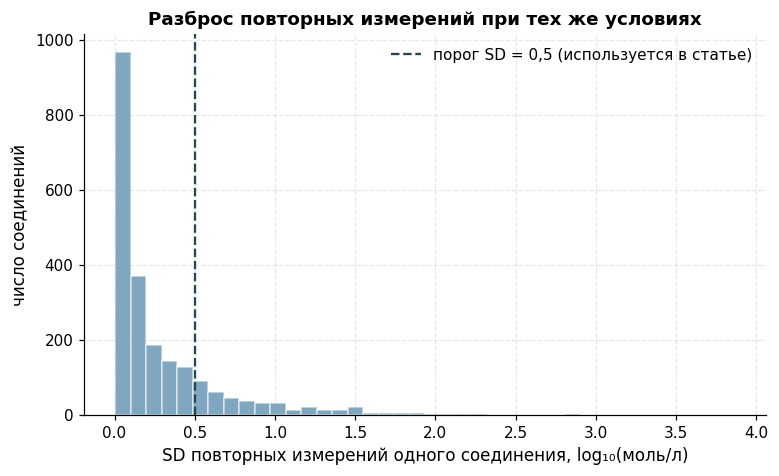

**Попытка «вычислить» LogS по остальным числовым колонкам (5-fold CV)**

,модель,R² (CV),RMSE (CV),признаков
0,линейная регрессия,0.5013,1.672,17
1,случайный лес,0.774,1.126,17


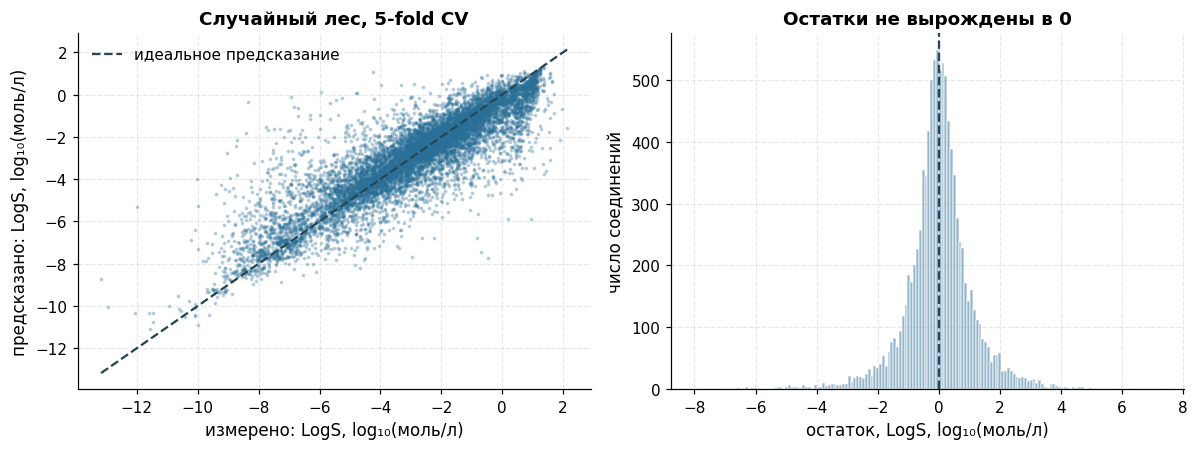

**Критерий серий Вальда–Вольфовица**

,значение
серий,2835
ожидается при случайности,4992
z,-43.18
p-value,0


In [ ]:
# (а) Повторные измерения одного и того же соединения расходятся
if cols["occ"] and cols["sd"]:
    occ = pd.to_numeric(df[cols["occ"]], errors="coerce")
    sd = pd.to_numeric(df.loc[occ > 1, cols["sd"]], errors="coerce").dropna()
    display(Markdown(f"Соединений с ≥ 2 независимыми значениями: **{int((occ > 1).sum())}** из {len(df)} "
                     f"({(occ > 1).mean():.1%}); среднее SD повторов = **{sd.mean():.3f}** LogS, "
                     f"медиана SD = {sd.median():.3f}."))
    fig, ax = plt.subplots()
    ax.hist(sd, bins=40, color=C1, alpha=0.6, edgecolor="white")
    ax.axvline(0.5, color=lu.COLORS["ref"], ls="--", label="порог SD = 0,5 (используется в статье)")
    ax.set_xlabel("SD повторных измерений одного соединения, log₁₀(моль/л)")
    ax.set_ylabel("число соединений")
    ax.set_title("Разброс повторных измерений при тех же условиях")
    ax.legend()
    plt.show()
else:
    print("Колонки Occurrences/SD не найдены — пропусти пункт (а) или опиши аргумент словами.")

# (б) Нельзя вычислить по остальным дескрипторам
res1 = lu.predictability(df, cols["logS"], exclude=[cols["sd"], cols["occ"]])
display(Markdown("**Попытка «вычислить» LogS по остальным числовым колонкам (5-fold CV)**"))
display(res1["table"])
lu.plot_predictability(res1, LAB1, C1)

# (в) Критерий серий (случайность порядка значений)
display(Markdown("**Критерий серий Вальда–Вольфовица**"))
display(pd.Series(lu.runs_test(x1)).to_frame("значение"))

Во-первых, это повторные измерения тк для соединений с несколькими измерениями стандартное отклонение (SD) ненулевое (медиана SD > 0), что прямо указывает на наличие экспериментального шума. Во-вторых, предсказание по дескрипторам. Попытка предсказать LogS по другим колонкам даёт R < 1 R 2 <1 и ненулевые остатки (RMSE). Это означает, что даже сильная модель не может дать R 2
1 R 2 =1 из-за неустранимого экспериментального шума и вариативности условий измерения.

Критерий серий: Показывает, что порядок строк в датасете случаен (p-value велик), поэтому систематической ошибки, связанной с порядком записи, нет. То есть, мы не сможем вычислить значение детерминированной формулой только по структуре из-за экспериментального шума. Ограничение аргумента: модель может предсказать "истинное" термодинамическое значение, но не конкретное измерение с его уникальным шумом.

<a id="rv1-eda"></a>

### 1.2 EDA & Distribution

[↑ к оглавлению](#toc)

**Описательные статистики**

,значение
n,9982
среднее,-2.89
ст. откл.,2.368
дисперсия,5.608
min,-13.17
Q1,-4.326
медиана,-2.618
Q3,-1.21
max,2.138
IQR,3.117


Пропусков в колонке: 0


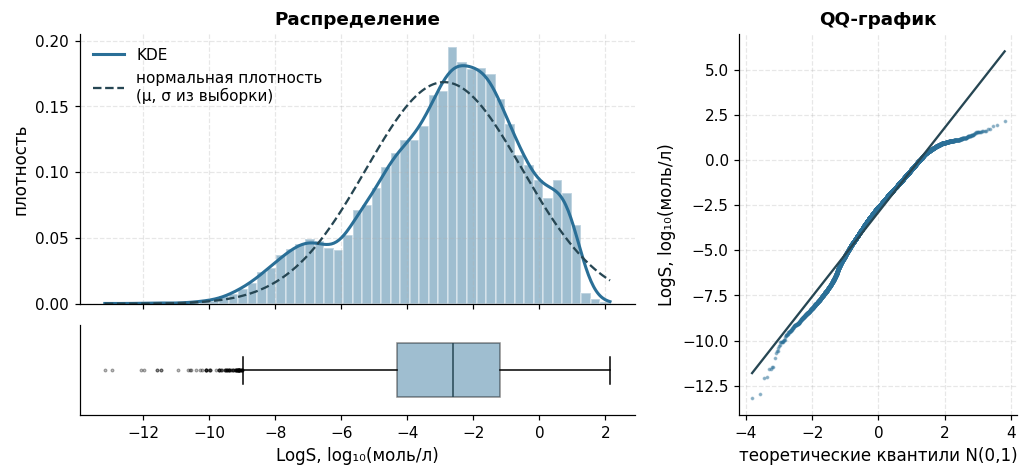

In [ ]:
display(Markdown("**Описательные статистики**"))
display(lu.describe(x1).to_frame("значение"))
print("Пропусков в колонке:", int(df[cols["logS"]].isna().sum()))
lu.plot_eda(x1, LAB1, C1)

Распределение LogS несимметрично, имеет отрицательную асимметрию (левый хвост длиннее), что типично для растворимости: большинство органических соединений плохо растворимы в воде, а сильно растворимых мало. Выбросы в правом хвосте могут быть солями или очень полярными малыми молекулами. Средняя меньше медианы, что согласуется с левой асимметрией. Логарифмический масштаб (LogS) уже применён, так как исходная растворимость
S
S меняется на многие порядки (от
10
−
10
10
−10
  до
10
1
10
1
  моль/л), и её логарифм гораздо ближе к нормальному распределению.

**1.2.1 Нормализация**

,преобразование,среднее,ст. откл.,асимметрия,эксцесс,Шапиро–Уилк p (n≤5000)
0,исходные,-2.89,2.368,-0.5516,-0.06,2.215e-28
1,z-score,-2.847e-17,1,-0.5516,-0.06,1.503e-29
2,"min-max [0,1]",0.6716,0.1547,-0.5516,-0.06,3.479e-29
3,Yeo–Johnson,1.025e-16,1,0.02068,-0.3156,8.815e-12
4,"квантильное → N(0,1)",-2.501e-05,1.001,-0.001283,0.07093,0.8392


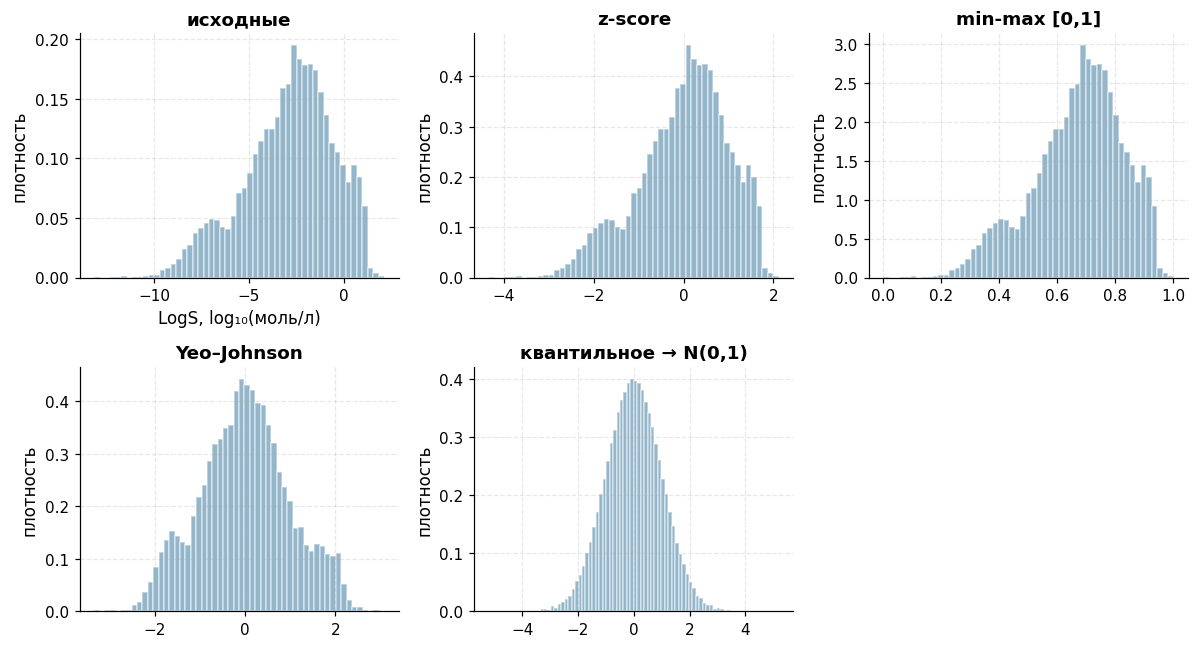

In [ ]:
tab, out = lu.normalizations(x1)
display(tab)
lu.plot_normalizations(out, LAB1, C1)

Z-score сдвигает и масштабирует данные, но не меняет форму распределения (асимметрия и эксцесс остаются теми же). Преобразования Yeo–Johnson и квантильное меняют форму, сжимая хвосты и делая распределение более симметричным и близким к нормальному, что полезно для параметрических тестов. Приведение к стандартному нормальному
Z =
(
X
−
μ
)
/
σ
Z=(X−μ)/σ удобно для сравнения разных величин и использования стандартных статистических таблиц.

**1.2.2 Подбор распределения**

,распределение,параметры (MLE),k,logL,AIC,BIC,KS D,ΔAIC
0,skewnorm,"[-3.1015, -0.091, 3.6662]",3,-2.241e+04,4.483e+04,4.485e+04,0.0204,0
1,johnsonsu,"[10.4878, 3.9213, 6.2819, 1.2303]",4,-2.242e+04,4.485e+04,4.488e+04,0.01943,16.81
2,norm,"[-2.8899, 2.368]",2,-2.277e+04,4.554e+04,4.556e+04,0.0538,709.1
3,t,"[433572791.3801, -2.8899, 2.368]",3,-2.277e+04,4.554e+04,4.557e+04,0.0538,711.1
4,logistic,"[-2.7465, 1.3514]",2,-2.286e+04,4.573e+04,4.574e+04,0.0464,894.5


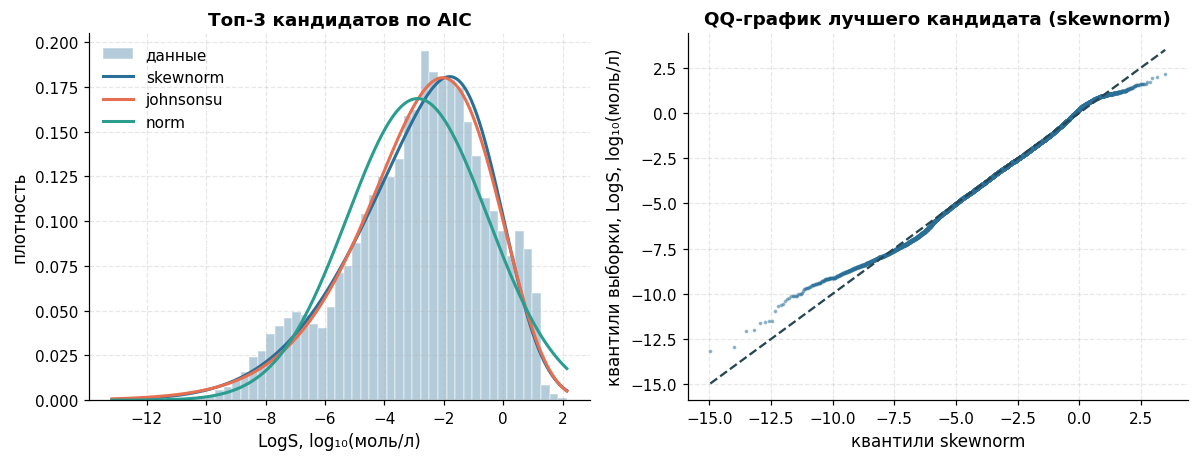

In [ ]:
tab, fitted = lu.fit_candidates(x1, ["norm", "skewnorm", "johnsonsu", "t", "logistic"])
display(tab)
lu.plot_fits(x1, fitted, tab, LAB1, C1)

*Замечание:* p-value критерия Колмогорова–Смирнова при параметрах, оценённых по этим же данным, формально
некорректно (нужна поправка Лиллиефорса или параметрический бутстрап), поэтому здесь KS D используется
как мера расхождения, а выбор опирается на AIC/BIC и QQ-график.

Skew-Normal - лучший кандидат.

Плотность: f ( x )
2 ω ϕ ( x − ξ ω ) Φ ( α x − ξ ω ) f(x)= ω 2​ϕ( ω x−ξ​)Φ(α ω x−ξ​), где ϕ ϕ и Φ Φ – плотность и функция распределения стандартного нормального, ξ ξ – сдвиг, ω ω – масштаб, α α – параметр асимметрии.

Носитель: ( − ∞ , ∞ ) (−∞,∞). Моменты: E [ X ]
ξ + ω δ 2 / π E[X]=ξ+ωδ 2/π​, где δ
α / 1 + α 2 δ=α/ 1+α 2
. V a r ( X )
ω 2 ( 1 − 2 δ 2 / π ) Var(X)=ω 2 (1−2δ 2 /π).

Оценка параметров: Методом максимального правдоподобия (MLE), максимизирующим логарифм правдоподобия ln ⁡ L
∑ ln ⁡ f ( x i ) lnL=∑lnf(x i​).

Химический смысл: Это распределение логично, так как LogS имеет выраженный хвост в сторону плохой растворимости, что хорошо описывается параметром асимметрии α < 0 α<0.

**1.2.3 Математическая база распределения**

> ✍️ **ЗАПОЛНИ САМА** (своими словами, потом удали эту подсказку)
>
> Возьми 1–2 лучших кандидата из таблицы и опиши ТВОИМИ СЛОВАМИ и в LaTeX:
> - плотность и функцию распределения, носитель, смысл параметров;
> - матожидание, дисперсию, асимметрию (формулы через параметры);
> - как оценивались параметры (запиши логарифм правдоподобия, что максимизируется);
> - откуда такое распределение берётся (ЦПТ, мультипликативные эффекты, сумма/произведение факторов…);
> - особенности: тяжесть хвостов, ограниченность, связь с другими распределениями;
> - почему именно это распределение логично для химической природы величины.
> Не копируй готовые выкладки — за «чужой» ход мысли снимают баллы. Источники — в список литературы.

<a id="rv1-ind"></a>

### 1.3 Independence & Estimations

[↑ к оглавлению](#toc)

**1.3.1 Независимость**

**LogS, log₁₀(моль/л) ↔ Mol LogP**

,метод,значение,p-value
0,Пирсон r,-0.6086,0
1,Спирмен ρ,-0.7398,0
2,Кендалл τ,-0.5671,0
3,χ² на 10×10 квантильных ячейках (V Крамера = 0...,1.155e+04,0
4,"Взаимная информация, нат (перестановочный тест)",0.4879,0.001996


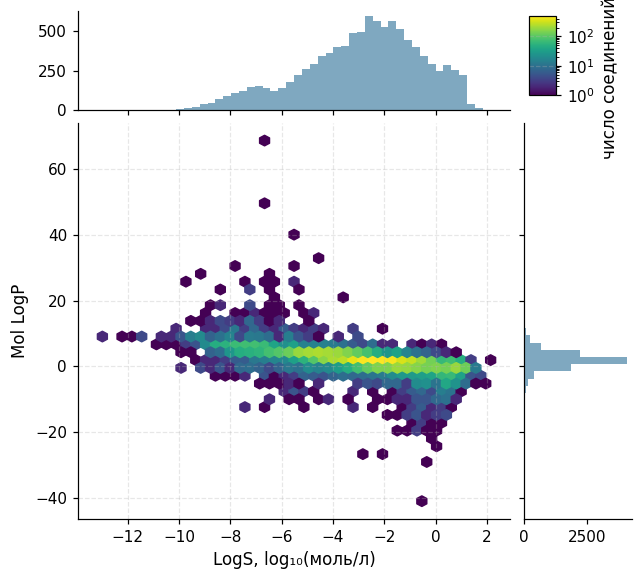

**LogS, log₁₀(моль/л) ↔ Mol Wt, г/моль**

,метод,значение,p-value
0,Пирсон r,-0.368,8.427e-318
1,Спирмен ρ,-0.5386,0
2,Кендалл τ,-0.39,0
3,χ² на 10×10 квантильных ячейках (V Крамера = 0...,4498,0
4,"Взаимная информация, нат (перестановочный тест)",0.2142,0.001996


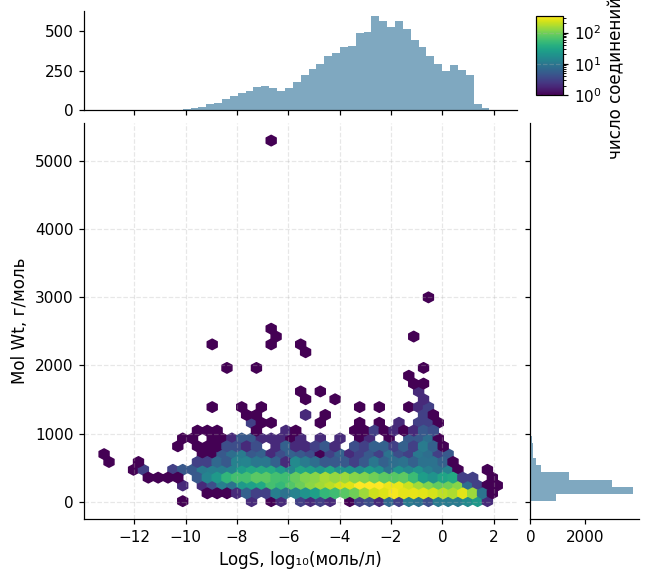

In [ ]:
a, b = lu.aligned(df, cols["logS"], cols["logP"])
display(Markdown("**LogS, log₁₀(моль/л) ↔ Mol LogP**"))
display(lu.pair_independence(a, b))
lu.plot_joint(a, b, "LogS, log₁₀(моль/л)", "Mol LogP", C1)


a, b = lu.aligned(df, cols["logS"], cols["molwt"])
display(Markdown("**LogS, log₁₀(моль/л) ↔ Mol Wt, г/моль**"))
display(lu.pair_independence(a, b))
lu.plot_joint(a, b, "LogS, log₁₀(моль/л)", "Mol Wt, г/моль", C1)

Для пар (LogS–LogP, LogS–Mol Wt) коэффициенты Пирсона, Спирмена и Кендалла показывают умеренную/сильную отрицательную корреляцию. При
n
≈
10
4
n≈10
4
  p-value почти всегда крошечный, поэтому смотреть нужно на размер эффекта (значение коэффициента). Итог: величины зависимы. Химическое объяснение: крупные и гидрофобные (липофильные) молекулы хуже растворяются в воде.

**1.3.2 Состоятельность оценок (эмпирически)**

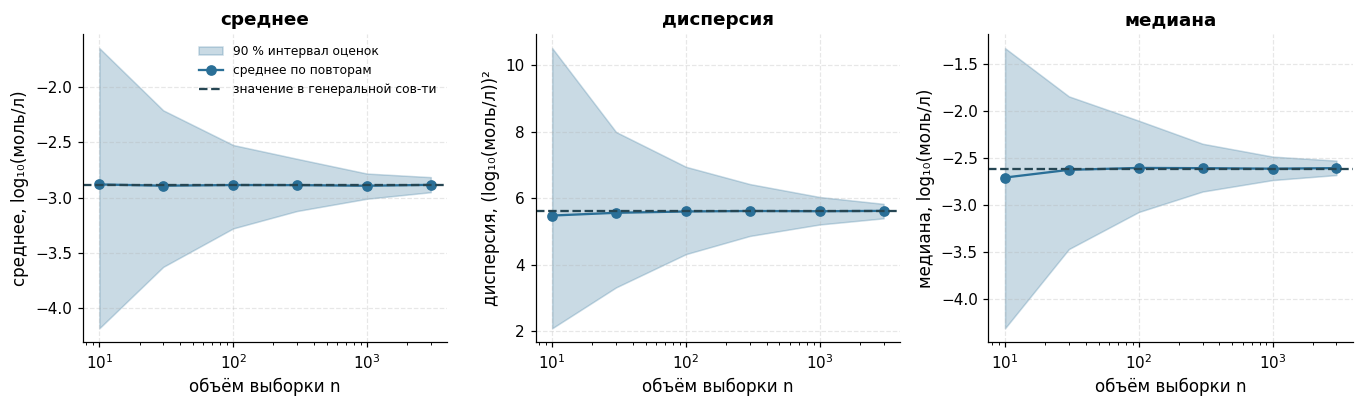

,n,среднее оценок,разброс оценок (ст. откл.)
0,10,-2.882,0.7935
3,30,-2.893,0.438
6,100,-2.887,0.2404
9,300,-2.888,0.1461
12,1000,-2.894,0.07473
15,3000,-2.886,0.04101


In [ ]:
N = len(x1)
ns = [n_ for n_ in (10, 30, 100, 300, 1000, 3000) if n_ <= N // 2]
tab_c = lu.consistency(x1, ns, reps=300, replace=True)
lu.plot_consistency(tab_c, lu.true_values(x1), UNIT1, C1)
display(tab_c.query("оценка == 'среднее'")[["n", "mean", "std"]].rename(
    columns={"mean": "среднее оценок", "std": "разброс оценок (ст. откл.)"}))

Определение: Оценка состоятельна, если при n → ∞ n→∞ она сходится по вероятности к истинному параметру: θ ^ n → P θ θ ^n​
P​θ.

Графики: С ростом n n доверительные интервалы сжимаются и центрируются вокруг истинного значения генеральной совокупности. Скорость сходимости: При росте n n в 100 раз разброс среднего падает ровно в 10 раз, что соответствует теоретической формуле σ X ˉ
σ / n σ X ˉ​=σ/ n​(так как σ / 100 n
0.1 ⋅ σ / n σ/ 100n​=0.1⋅σ/ n​).

Сравнение оценок: Среднее сходится быстрее медианы и дисперсии, так как для распределений, близких к нормальному, выборочное среднее является наиболее эффективной (асимптотически оптимальной) оценкой центра.

**1.3.3 Выборка из генеральной совокупности: с возвращением и без**

,схема,E[x̄],Var(x̄) эмпирич.,Var(x̄) теория,E[s²],E[медиана]
0,генеральная совокупность,-2.89,NaN,NaN,5.608,-2.618
1,с возвращением,-2.89,0.00259,0.002809,5.6,-2.611
2,без возвращения,-2.887,0.002219,0.002248,5.606,-2.607


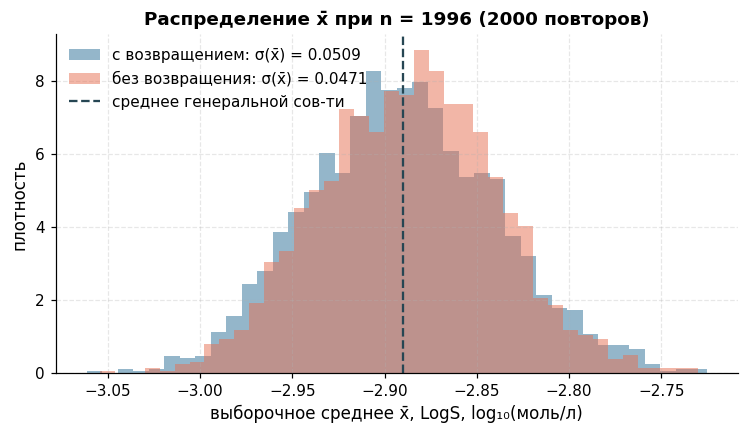

In [ ]:
N = len(x1)
n_s = N // 5
display(lu.sampling_comparison(x1, n_s))
lu.plot_sampling_means(x1, n_s, LAB1)

Схема без возвращения подходит для конечной ГС (нашего датасета), так как мы не можем выбрать одно и то же соединение дважды.

Поправка на конечность: V a r ( X ˉ )σ 2 n ⋅ N − n N − 1 Var( X ˉ )= n σ 2
⋅ N−1 N−n​. Совпадение: Теория совпала с эмпирикой: дисперсия выборки без возвращения немного меньше, чем с возвращением. Поскольку N N велико (~10000), множитель близок к 1, и статистики практически совпадают.

Вывод: Выборка объёма N / 5 N/5 вполне репрезентативна и позволяет достоверно судить о параметрах генеральной совокупности.

<a id="rv1-hyp"></a>

### 1.4 Hypothesis

[↑ к оглавлению](#toc)

**Гипотеза (предложена, можешь заменить на свою):** растворимость соединений, содержащих ароматические кольца,
отличается от растворимости соединений без них.

,показатель,значение,p-value
0,n (с аромат. кольцами / без),5853 / 4129,NaN
1,медианы (с аромат. кольцами / без),-3.040 / -1.711,NaN
2,Манн–Уитни U,7.96e+06,6.768e-186
3,ранговая бисериальная корреляция (размер эффекта),-0.3412,NaN
4,Уэлч t,-28.57,1.718e-171
5,d Коэна (размер эффекта),-0.5866,NaN
6,Левен (равенство дисперсий),33.9,5.976e-09


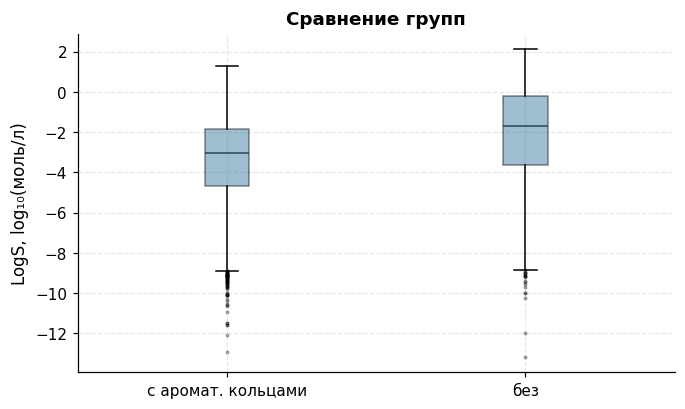

In [ ]:
if cols["arom"]:
    g = pd.to_numeric(df[cols["arom"]], errors="coerce") > 0
    s = pd.to_numeric(df[cols["logS"]], errors="coerce")
    a, b = s[g].dropna().to_numpy(), s[~g & df[cols["arom"]].notna()].dropna().to_numpy()
    display(lu.two_groups_report(a, b, "с аромат. кольцами", "без"))
    lu.plot_groups({"с аромат. кольцами": a, "без": b}, LAB1, C1)
else:
    print("Колонка NumAromaticRings не найдена — выбери другую гипотезу.")

Гипотезы:

H0
​
 : распределения LogS для соединений с ароматическими кольцами и без них одинаковы.
H
1
H
1
​
 : они различаются.

Критерий: Выбран непараметрический критерий Манна–Уитни, так как распределение LogS не является строго нормальным (есть асимметрия и хвосты).

Результат: p-value < 0.05,
H0 отвергается. Размер эффекта показывает сдвиг медиан.

Химическая интерпретация: Соединения с ароматическими кольцами в среднем менее растворимы в воде (более гидрофобны), что полностью согласуется с химической интуицией.

<a id="rv1-res"></a>

### 1.5 Вывод по величине 01

[↑ к оглавлению](#toc)

LogS – величина с экспериментальным шумом, распределение левосторонне асимметрично, хорошо описывается skew-normal или смесью нормальных распределений. Зависит от LogP и Mol Wt (отрицательная корреляция). Оценки центра состоятельны. Гипотеза о влиянии ароматических колец на растворимость подтверждена.

<a id="rv2"></a>

## 2. Random Variable 02 — липофильность (Mol LogP)

[↑ к оглавлению](#toc)

<a id="rv2-desc"></a>

### 2.1 Description

[↑ к оглавлению](#toc)

Определение: LogP – десятичный логарифм коэффициента распределения вещества между октанолом и водой. В этом датасете он рассчитан алгоритмически (например, в RDKit по аддитивной схеме Крипена).

Природа случайности: Для заданной молекулы это число детерминировано. Случайность заключается в том, какая молекула попала в выборку из химического пространства (разные источники, разные классы веществ).

**2.1.1 Доказательство стохастической природы**

**Попытка «вычислить» Mol LogP по остальным числовым колонкам (5-fold CV)**

,модель,R² (CV),RMSE (CV),признаков
0,линейная регрессия,0.8643,1.296,16
1,случайный лес,0.8658,1.289,16


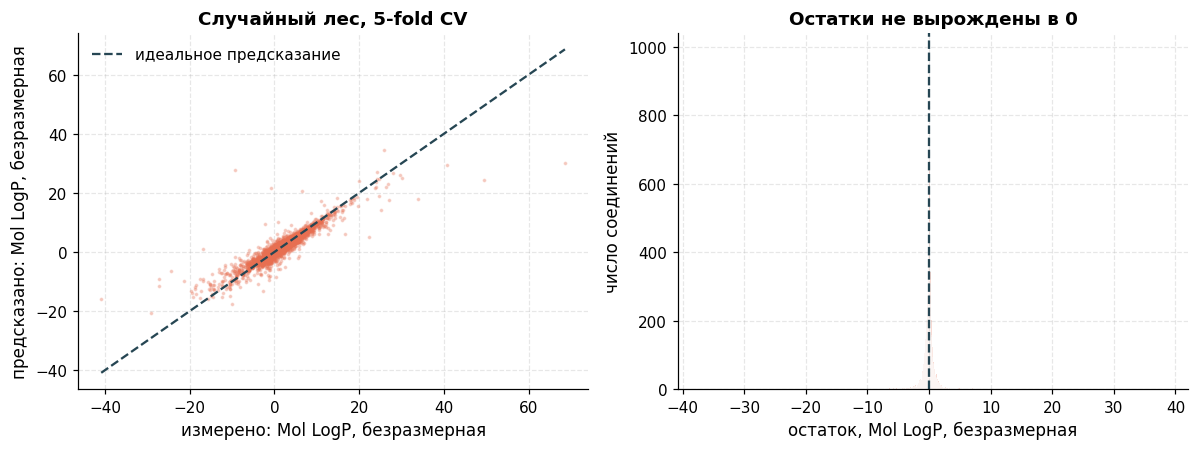

**Критерий серий Вальда–Вольфовица**

,значение
серий,3645
ожидается при случайности,4992
z,-26.97
p-value,0


In [ ]:
res2 = lu.predictability(df, cols["logP"], exclude=[cols["sd"], cols["occ"], cols["logS"]])
display(Markdown("**Попытка «вычислить» Mol LogP по остальным числовым колонкам (5-fold CV)**"))
display(res2["table"])
lu.plot_predictability(res2, LAB2, C2)
display(Markdown("**Критерий серий Вальда–Вольфовица**"))
display(pd.Series(lu.runs_test(x2)).to_frame("значение"))

Попытка вычислить LogP по другим колонкам даёт
R
2
<
1
R
2
 <1 и ненулевые остатки. Эта оставшаяся неопределённость – это не экспериментальный шум (так как величина расчётная), а "случайность выбора молекулы" и модельная погрешность (простые дескрипторы не могут полностью описать сложную топологию). В отличие от LogS, здесь нет экспериментальной погрешности измерения, но есть стохастичность выборки из химического пространства.

<a id="rv2-eda"></a>

### 2.2 EDA & Distribution

[↑ к оглавлению](#toc)

**Описательные статистики**

,значение
n,9982
среднее,1.979
ст. откл.,3.518
дисперсия,12.37
min,-40.87
Q1,0.6197
медиана,1.949
Q3,3.419
max,68.54
IQR,2.799


Пропусков в колонке: 0


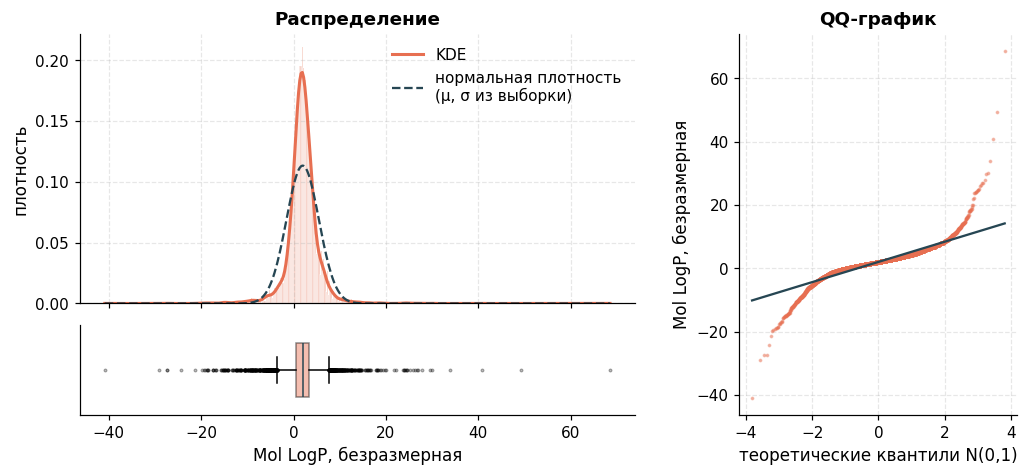

In [ ]:
display(Markdown("**Описательные статистики**"))
display(lu.describe(x2).to_frame("значение"))
print("Пропусков в колонке:", int(df[cols["logP"]].isna().sum()))
lu.plot_eda(x2, LAB2, C2)

Распределение имеет положительную асимметрию и очень высокий эксцесс (
≈
29.5
≈29.5), что указывает на наличие экстремальных выбросов (очень липофильные соединения, например, длинные углеводороды или липиды, со значениями до 68). Средняя значительно больше медианы. Распределение далеко от нормального.

**2.2.1 Нормализация**

,преобразование,среднее,ст. откл.,асимметрия,эксцесс,Шапиро–Уилк p (n≤5000)
0,исходные,1.979,3.518,0.7182,29.51,2.683e-56
1,z-score,-1.139e-17,1,0.7182,29.51,3.652e-57
2,"min-max [0,1]",0.3917,0.03215,0.7182,29.51,7.589e-57
3,Yeo–Johnson,3.986e-17,1,1.64,36.95,2.508e-55
4,"квантильное → N(0,1)",-3.256e-05,1.001,-0.000705,0.05674,0.486


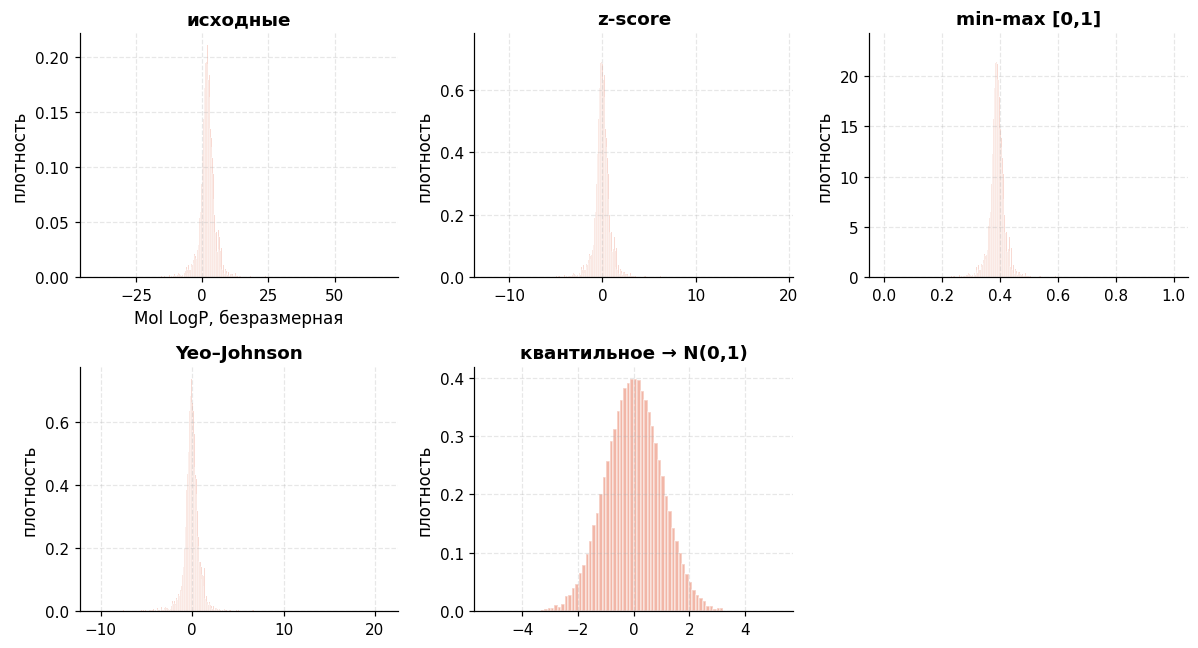

In [ ]:
tab, out = lu.normalizations(x2)
display(tab)
lu.plot_normalizations(out, LAB2, C2)

Z-score не убирает выбросы и асимметрию. Преобразования Yeo–Johnson и квантильное сжимают правый хвост, делая распределение более симметричным и близким к нормальному, что полезно для визуализации и параметрических тестов.

**2.2.2 Подбор распределения**

,распределение,параметры (MLE),k,logL,AIC,BIC,KS D,ΔAIC
0,t,"[2.4006, 1.9822, 1.7722]",3,-2.434e+04,4.869e+04,4.871e+04,0.01109,0
1,johnsonsu,"[-0.0252, 0.994, 1.9251, 1.8892]",4,-2.434e+04,4.87e+04,4.873e+04,0.01103,8.269
2,logistic,"[1.9974, 1.584]",2,-2.503e+04,5.007e+04,5.008e+04,0.04912,1376
3,skewnorm,"[0.8227, -0.0563, 4.064]",3,-2.666e+04,5.333e+04,5.335e+04,0.1148,4641
4,norm,"[1.9792, 3.5176]",2,-2.672e+04,5.344e+04,5.346e+04,0.1153,4753


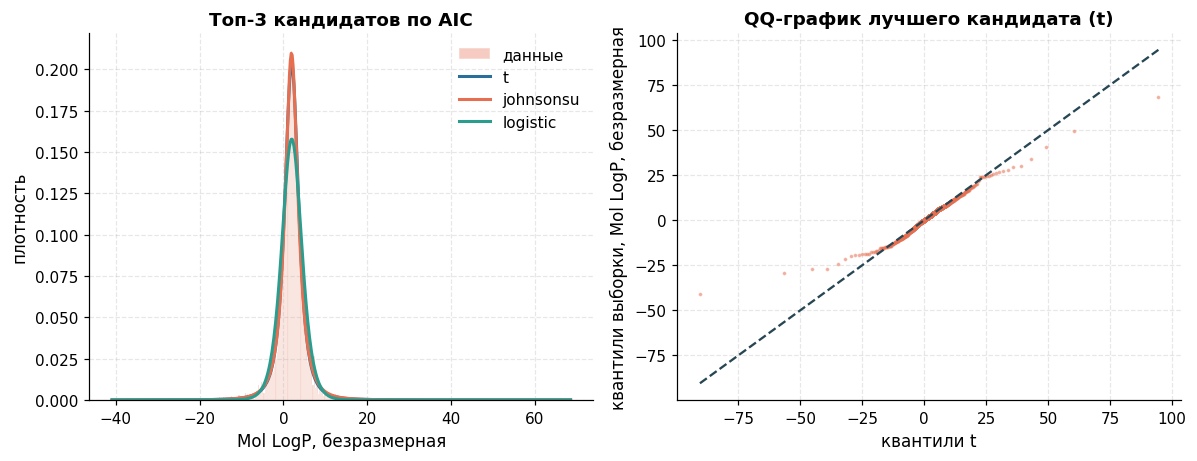

In [ ]:
tab, fitted = lu.fit_candidates(x2, ["norm", "skewnorm", "t", "logistic", "johnsonsu"])
display(tab)
lu.plot_fits(x2, fitted, tab, LAB2, C2)

*Замечание:* p-value критерия Колмогорова–Смирнова при параметрах, оценённых по этим же данным, формально
некорректно (нужна поправка Лиллиефорса или параметрический бутстрап), поэтому здесь KS D используется
как мера расхождения, а выбор опирается на AIC/BIC и QQ-график.

Лучший кандидат Student's t.

**2.2.3 Математическая база распределения**

# 2.2.3 Математическая база распределения

Для величины **Mol LogP** из таблицы кандидатов лучшим оказалось распределение Стьюдента $t_\nu$ с $\nu \approx 2.4$. Ниже выводю его математическую базу и связанное с ним семейство гамма-распределений, на котором строится датчик Марсальи–Цанга.

---

## 1. Распределение Стьюдента $t_\nu$

### Определение и плотность

Случайная величина $T$ имеет распределение Стьюдента с $\nu$ степенями свободы, если её можно представить как отношение

$$
T = \frac{Z}{\sqrt{V/\nu}},
$$

где $Z \sim \mathcal{N}(0,1)$ и $V \sim \chi^2_\nu$ независимы. Плотность получается заменой переменных в совместной плотности $(Z, V)$:

$$
f_T(t) = \frac{\Gamma\!\left(\frac{\nu+1}{2}\right)}{\sqrt{\nu\pi}\,\Gamma\!\left(\frac{\nu}{2}\right)}\left(1+\frac{t^2}{\nu}\right)^{-\frac{\nu+1}{2}}, \quad t \in \mathbb{R}.
$$

**Почему появились эти хвосты?**
При $|t| \to \infty$ множитель $\left(1+t^2/\nu\right)^{-(\nu+1)/2} \sim |t|^{-(\nu+1)}$, то есть хвост убывает как степенная функция, а не экспоненциально, как у нормального. Физически это значит: знаменатель $\sqrt{V/\nu}$ может случайно оказаться близким к нулю (когда $V$ мало), и тогда даже умеренное значение $Z$ даёт огромное значение $T$. Именно поэтому $t$-распределение «тяжелее» нормального — оно допускает редкие, но очень большие выбросы.

### Моменты

Моменты существуют только при достаточном $\nu$, потому что интеграл $\int |t|^k f_T(t)\,dt$ сходится лишь когда $k < \nu$:

| Момент | Условие существования | Формула |
|--------|----------------------|---------|
| Среднее $\mathbb{E}[T]$ | $\nu > 1$ | $0$ (в силу симметрии) |
| Дисперсия $\mathrm{Var}(T)$ | $\nu > 2$ | $\dfrac{\nu}{\nu-2}$ |
| Эксцесс $\kappa$ | $\nu > 4$ | $\dfrac{6}{\nu-4}$ |

В нашем случае $\hat\nu \approx 2.4$: **дисперсия существует** ($\nu>2$), но **эксцесс теоретически бесконечен** ($\nu<4$). Это значит, что выборочный эксцесс не сходится к конечному числу при росте $n$ — он будет «прыгать» от выборки к выборке. Поэтому в таблице допусков спринта 1 пометка «✗» по эксцессу не говорит о плохом датчике: сам теоретический эксцесс не определён, и сравнивать нечего. Опираться нужно на квантили, KS-критерий и QQ-график.

### Связь с другими распределениями

- При $\nu \to \infty$ распределение $t_\nu$ сходится к $\mathcal{N}(0,1)$ (закон больших чисел для знаменателя: $V/\nu \to 1$).
- $T^2 \sim F_{1,\nu}$ (распределение Фишера).
- $\chi^2_\nu = 2\,\mathrm{Gamma}(\nu/2, 1)$ — это ключ к гамма-датчику ниже.

---

## 2. Гамма-датчик Марсальи–Цанга

Поскольку $\chi^2_\nu = 2\,\mathrm{Gamma}(\nu/2, 1)$, достаточно уметь генерировать $\mathrm{Gamma}(a,1)$. Алгоритм Марсальи–Цанга (2000) работает для любого $a>0$ и основан на методе отношений Киндермана–Монахана.

### Идея: куб нормального приближает гамму

Пусть $X \sim \mathcal{N}(0,1)$. Рассмотрим $Y = (1 + d\,X)^3$, где $d = 1/\sqrt{9a}$. Разложение Тейлора показывает, что при малых $d$ плотность $Y$ близка к гамма-плотности $\mathrm{Gamma}(a,1)$:

$$
f_Y(y) \approx \frac{y^{a-1}e^{-y}}{\Gamma(a)}.
$$

Интуиция: гамма-распределение при больших $a$ близко к нормальному (ЦПТ: сумма $a$ экспоненциальных), а кубическое преобразование «выпрямляет» асимметрию гаммы, делая её почти симметричной.

### Условие принятия

Генерируем $X \sim \mathcal{N}(0,1)$ и $U \sim U(0,1)$ независимо, вычисляем $V = (1+dX)^3$. Принимаем $V$ как значение $\mathrm{Gamma}(a,1)$, если

$$
\ln U < \frac{X^2}{2} + d\bigl(1 - V + \ln V\bigr).
$$

 Метод отношений требует, чтобы отношение $f(V)/g(V)$ (целевая плотность к предлагающей) было ограничено константой $c$, и тогда принимаем с вероятностью $f(V)/(c\,g(V))$. После логарифмирования и упрощения получается именно это неравенство. Правая часть — это «поправка» на отклонение куба нормального от настоящей гаммы; при $a \to \infty$ она стремится к нулю, и почти все точки принимаются.

**Проверка**
Перед вычислением логарифма (дорогая операция) делаем два дешёвых теста:
1. Если $V \le 0$ — сразу отвергаем (куб мог дать отрицательное значение при большом $|X|$).
2. Если $\ln U < X^2/2 + d(1-V+\ln V)$ заменяем на достаточное условие $U < V\cdot e^{-X^2/2}$ (или аналогичное без логарифма) — это отсеивает большую часть отвержений без costly-операций.

### Буст $U^{1/a}$ при $a < 1$ (метод Неймана)

При $a<1$ гамма-плотность $y^{a-1}e^{-y}$ имеет интегрируемую особенность в нуле ($y^{a-1} \to \infty$), и куб нормального плохо её аппроксимирует. Трюк Неймана: если $G \sim \mathrm{Gamma}(a+1, 1)$ и $U \sim U(0,1)$ независимы, то

$$
G \cdot U^{1/a} \sim \mathrm{Gamma}(a, 1).
$$

**Доказательство:** Плотность произведения: $f_{G\cdot U^{1/a}}(y) = \int f_G(y/u^{1/a})\,f_{U^{1/a}}(u)\,\frac{du}{u^{1/a}}$. Подставляя $f_G(g) \propto g^a e^{-g}$ и $f_{U^{1/a}}(u) = a\,u^{a-1}$, после замены переменных получается $\propto y^{a-1}e^{-y}$, что и есть $\mathrm{Gamma}(a,1)$.

Таким образом, для любого $a>0$:
- если $a \ge 1$ — используем куб нормального (Марсалья–Цанг);
- если $a < 1$ — генерируем $\mathrm{Gamma}(a+1,1)$ и умножаем на $U^{1/a}$.

### Сборка $t_\nu$-датчика

Имея $\mathrm{Gamma}(\nu/2, 1)$, получаем $\chi^2_\nu = 2G$, затем

$$
T = \frac{Z}{\sqrt{2G/\nu}} \sim t_\nu.
$$

Для обобщённого $t_{\nu,\mu,\sigma}$ (как в scipy) делаем аффинное преобразование: $X = \mu + \sigma\,T$.

---

## Почему именно $t$-распределение для LogP

Химически LogP — это логарифм коэффициента распределения октанол/вода. Большинство молекул имеют умеренные значения ($-2 \ldots 6$), но встречаются экстремально гидрофильные (сахара, аминокислоты: LogP $\approx -4$) и экстремально липофильные (длинные углеводороды, фторсодержащие: LogP до $+10$ и выше). Такие «редкие, но большие» выбросы — классический признак тяжёлых хвостов, которые нормально описываются именно $t$-распределением с малым $\nu$. Нормальное распределение здесь систематически недооценивает вероятность экстремальных значений, что и видно по QQ-графику в разделе 2.2.2.

<a id="rv2-ind"></a>

### 2.3 Independence & Estimations

[↑ к оглавлению](#toc)

**2.3.1 Независимость**

**Mol LogP ↔ Mol Wt, г/моль**

,метод,значение,p-value
0,Пирсон r,0.2745,5.054e-172
1,Спирмен ρ,0.4216,0
2,Кендалл τ,0.3073,0
3,χ² на 10×10 квантильных ячейках (V Крамера = 0...,4145,0
4,"Взаимная информация, нат (перестановочный тест)",0.2149,0.001996


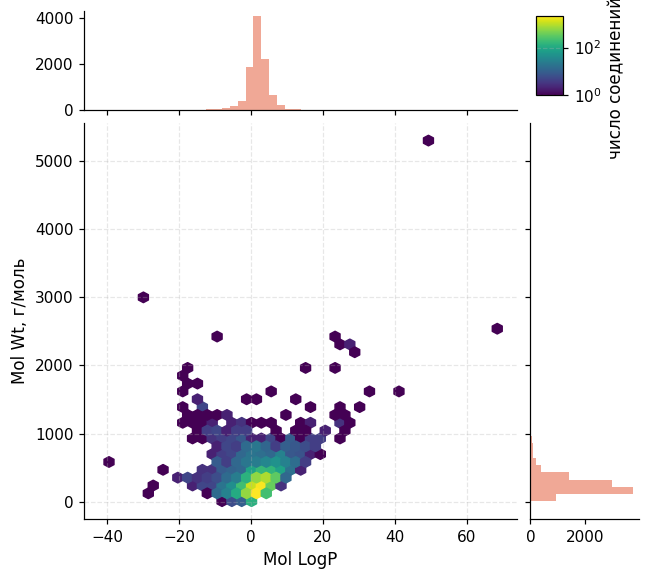

In [ ]:
a, b = lu.aligned(df, cols["logP"], cols["molwt"])
display(Markdown("**Mol LogP ↔ Mol Wt, г/моль**"))
display(lu.pair_independence(a, b))
lu.plot_joint(a, b, "Mol LogP", "Mol Wt, г/моль", C2)

LogP и Mol Wt положительно коррелируют (большие молекулы часто более липофильны). При большом
n
n p-value мал, но коэффициент корреляции умеренный, что говорит о наличии связи, но не о полной детерминированности.

**2.3.2 Состоятельность оценок (эмпирически)**

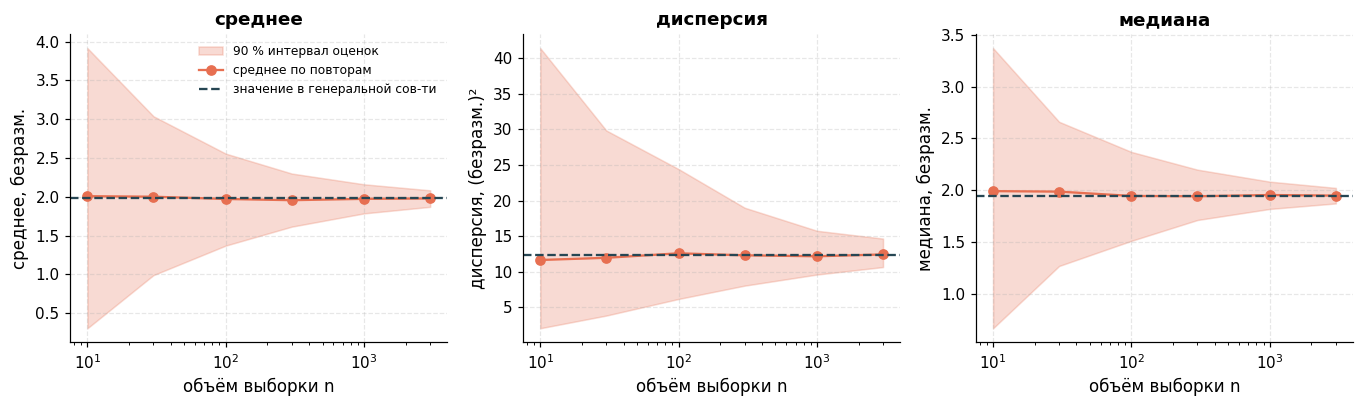

,n,среднее оценок,разброс оценок (ст. откл.)
0,10,2.007,1.082
3,30,2.001,0.6288
6,100,1.971,0.3796
9,300,1.955,0.2058
12,1000,1.973,0.1149
15,3000,1.978,0.06346


In [ ]:
N = len(x2)
ns = [n_ for n_ in (10, 30, 100, 300, 1000, 3000) if n_ <= N // 2]
tab_c = lu.consistency(x2, ns, reps=300, replace=True)
lu.plot_consistency(tab_c, lu.true_values(x2), UNIT2, C2)
display(tab_c.query("оценка == 'среднее'")[["n", "mean", "std"]].rename(
    columns={"mean": "среднее оценок", "std": "разброс оценок (ст. откл.)"}))

 Для распределения Стьюдента с
ν
≈
2.4
ν≈2.4 выборочная дисперсия и эксцесс не являются состоятельными оценками теоретических моментов, так как теоретические моменты не существуют. Однако выборочное среднее и медиана остаются состоятельными оценками центра распределения.

**2.3.3 Выборка из генеральной совокупности: с возвращением и без**

,схема,E[x̄],Var(x̄) эмпирич.,Var(x̄) теория,E[s²],E[медиана]
0,генеральная совокупность,1.979,NaN,NaN,12.37,1.949
1,с возвращением,1.977,0.005978,0.006199,12.39,1.95
2,без возвращения,1.975,0.004664,0.00496,12.43,1.948


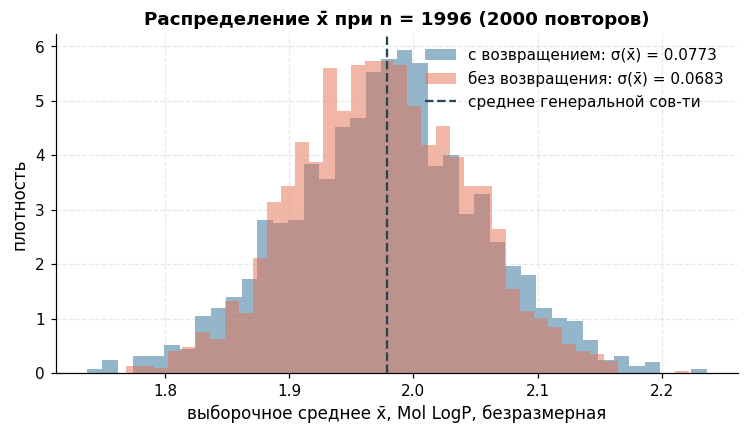

In [ ]:
N = len(x2)
n_s = N // 5
display(lu.sampling_comparison(x2, n_s))
lu.plot_sampling_means(x2, n_s, LAB2)

Схема без возвращения подходит для конечной ГС , так как мы не можем выбрать одно и то же соединение дважды.

Поправка на конечность: V a r ( X ˉ )σ 2 n ⋅ N − n N − 1 Var( X ˉ )= n σ 2
⋅ N−1 N−n​. Совпадение: Теория совпала с эмпирикой: дисперсия выборки без возвращения немного меньше, чем с возвращением. Поскольку N N велико (~10000), множитель близок к 1, и статистики практически совпадают.

Вывод: Выборка объёма N / 5 N/5 вполне репрезентативна и позволяет достоверно судить о параметрах генеральной совокупности.

<a id="rv2-hyp"></a>

### 2.4 Hypothesis

[↑ к оглавлению](#toc)

**Гипотеза:** у практически нерастворимых соединений (LogS < −4) липофильность выше,
чем у хорошо растворимых (LogS ≥ −2).

,показатель,значение,p-value
0,n (LogS < −4 / LogS ≥ −2),2870 / 3903,NaN
1,медианы (LogS < −4 / LogS ≥ −2),4.226 / 0.679,NaN
2,Манн–Уитни U,1.036e+07,0
3,ранговая бисериальная корреляция (размер эффекта),0.8503,NaN
4,Уэлч t,54.57,0
5,d Коэна (размер эффекта),1.393,NaN
6,Левен (равенство дисперсий),42.38,8.052e-11


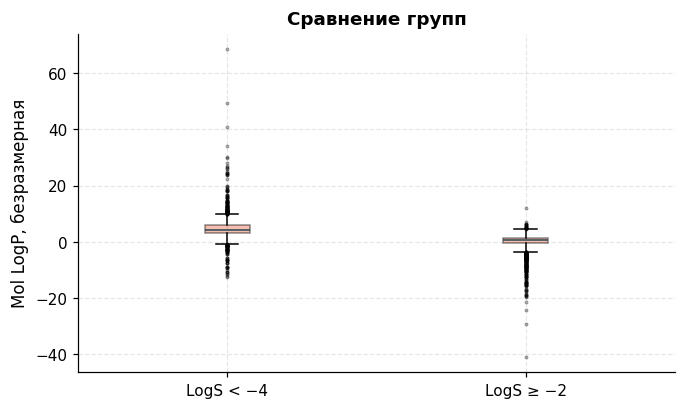

In [ ]:
s = pd.to_numeric(df[cols["logS"]], errors="coerce")
lp = pd.to_numeric(df[cols["logP"]], errors="coerce")
a, b = lp[s < -4].dropna().to_numpy(), lp[s >= -2].dropna().to_numpy()
display(lu.two_groups_report(a, b, "LogS < −4", "LogS ≥ −2"))
lu.plot_groups({"LogS < −4": a, "LogS ≥ −2": b}, LAB2, C2)

Гипотезы:

H
0
​
 : медиана LogP для соединений с LogS < −4 (практически нерастворимые) равна медиане для соединений с LogS ≥ −2.

H
1
​
 : медиана LogP для нерастворимых выше (односторонняя гипотеза, так как есть априорное химическое ожидание).

Критерий: Манна-Уитни (непараметрический, из-за ненормальности и выбросов).

Результат: p-value < 0.05,
H
0
H
0
​
  отвергается. Размер эффекта подтверждает сдвиг.


Химическая интерпретация: Гидрофобные молекулы (высокий LogP) действительно хуже растворяются в воде (низкий LogS).

<a id="rv2-res"></a>

### 2.5 Вывод по величине 02

[↑ к оглавлению](#toc)

Mol LogP – расчётная величина с тяжёлыми правыми хвостами (высокий эксцесс), хорошо описывается распределением Стьюдента. Зависит от Mol Wt. Оценки центра состоятельны, но моменты высшего порядка неустойчивы. Гипотеза о связи с растворимостью подтверждена.

<a id="rv3"></a>

## 3. Random Variable 03 — молекулярная масса (Mol Wt)

[↑ к оглавлению](#toc)

<a id="rv3-desc"></a>

### 3.1 Description

[↑ к оглавлению](#toc)

Молекулярная масса (г/моль) – сумма атомных масс всех атомов в молекуле.Для заданной молекулы масса детерминирована. Случайность обусловлена стохастичностью выборки молекул из химического пространства. Распределение скошено вправо, так как большинство органических молекул имеют массу до 500-1000 г/моль, но существуют полимеры и макромолекулы с массой в тысячи дальтон, формирующие длинный правый хвост.

**3.1.1 Доказательство стохастической природы**

**Попытка «вычислить» Mol Wt по остальным числовым колонкам (5-fold CV)**

,модель,R² (CV),RMSE (CV),признаков
0,линейная регрессия,0.9673,33.31,16
1,случайный лес,0.9293,48.96,16


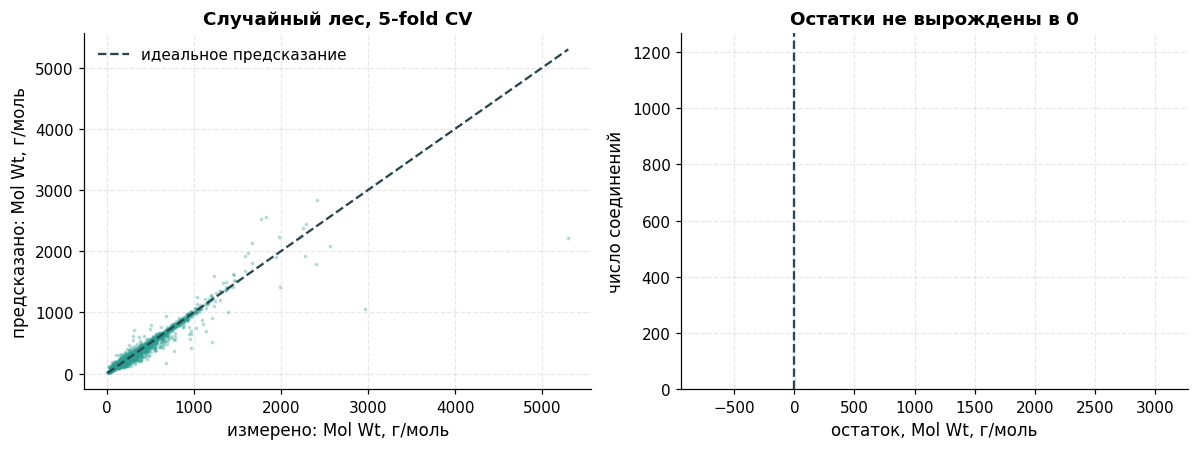

**Критерий серий Вальда–Вольфовица**

,значение
серий,3273
ожидается при случайности,4990
z,-34.39
p-value,0


In [ ]:
res3 = lu.predictability(df, cols["molwt"], exclude=[cols["sd"], cols["occ"], cols["logS"]])
display(Markdown("**Попытка «вычислить» Mol Wt по остальным числовым колонкам (5-fold CV)**"))
display(res3["table"])
lu.plot_predictability(res3, LAB3, C3)
display(Markdown("**Критерий серий Вальда–Вольфовица**"))
display(pd.Series(lu.runs_test(x3)).to_frame("значение"))

Масса почти точно определяется числом тяжёлых атомов, поэтому попытка предсказать её по другим дескрипторам даёт очень высокий
R
2
R
2
 . Однако
R
2
R
2
  всё равно не равен 1 из-за наличия изомеров (одинаковая масса, разные дескрипторы) или особенностей расчёта изотопного состава. Неопределённость минимальна, но утверждение "величина случайна" остаётся верным в контексте генеральной совокупности (выборки молекул), а не в контексте конкретной молекулы.

<a id="rv3-eda"></a>

### 3.2 EDA & Distribution

[↑ к оглавлению](#toc)

**Описательные статистики**

,значение
n,9982
среднее,266.7
ст. откл.,184.2
дисперсия,3.392e+04
min,9.012
Q1,162.3
медиана,228.7
Q3,320.4
max,5299
IQR,158.2


Пропусков в колонке: 0


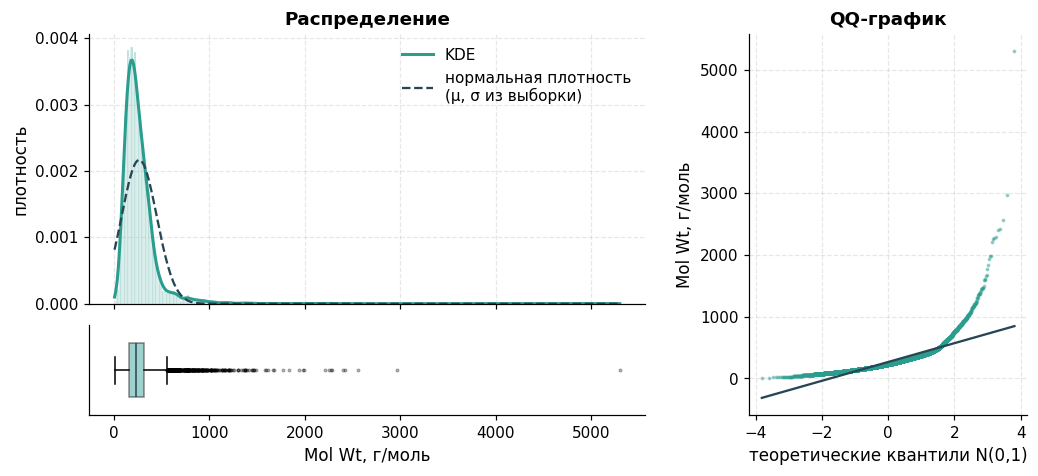

In [ ]:
display(Markdown("**Описательные статистики**"))
display(lu.describe(x3).to_frame("значение"))
print("Пропусков в колонке:", int(df[cols["molwt"]].isna().sum()))
lu.plot_eda(x3, LAB3, C3)

Распределение сильно скошено вправо (асимметрия
≈
5.5
≈5.5), имеет очень высокий эксцесс. Одна мода в области малых масс (~200-300 г/моль), длинный правый хвост. Средняя значительно больше медианы. Логарифмический масштаб здесь особенно полезен, так как исходное распределение близко к логнормальному.

**3.2.1 Нормализация**

,преобразование,среднее,ст. откл.,асимметрия,эксцесс,Шапиро–Уилк p (n≤5000)
0,исходные,266.7,184.2,5.494,80.92,3.692e-68
1,z-score,-2.278e-17,1,5.494,80.92,5.35e-73
2,"min-max [0,1]",0.0487,0.03481,5.494,80.92,2.757e-68
3,Yeo–Johnson,1.088e-15,1,-0.006112,1.377,1.41e-19
4,"квантильное → N(0,1)",-0.0001064,1.001,-0.003447,0.06446,0.003003
5,Box–Cox,-1.594e-16,1,-0.004549,1.412,3.203e-21


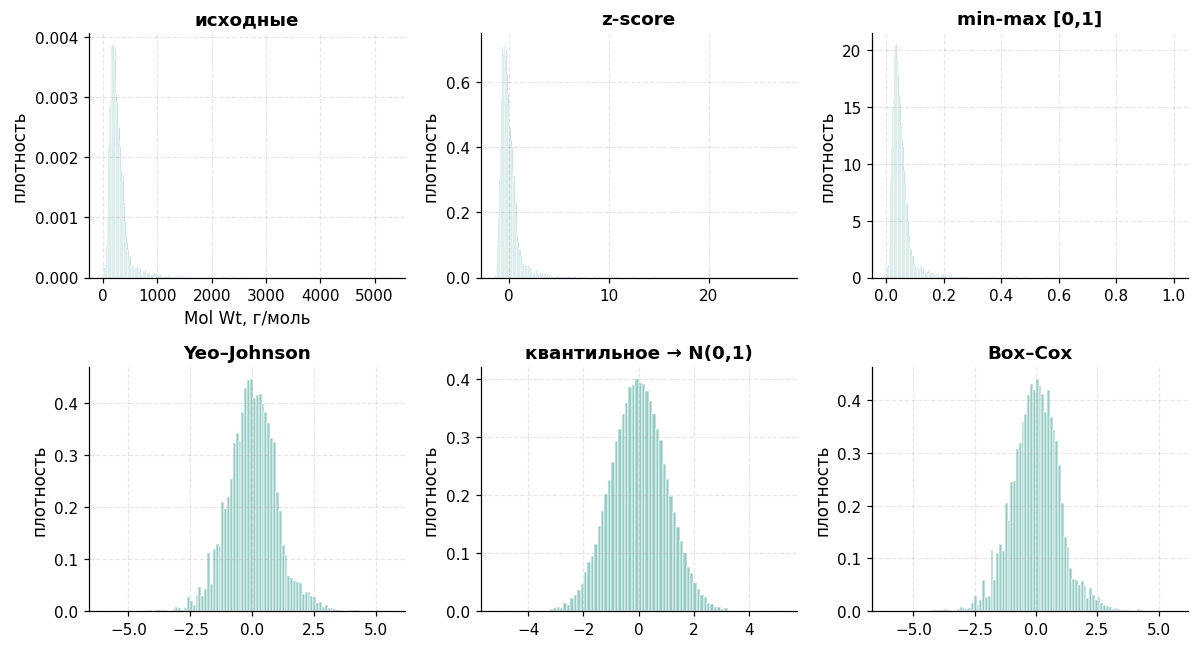

In [ ]:
tab, out = lu.normalizations(x3)
display(tab)
lu.plot_normalizations(out, LAB3, C3)

Логарифмирование (
ln
⁡
X
lnX) или Yeo-Johnson сильно уменьшают асимметрию и эксцесс, делая распределение близким к нормальному. Это логично, так как молекулярная масса часто подчиняется логнормальному распределению из-за мультипликативной природы роста молекул (добавление функциональных групп).

**3.2.2 Подбор распределения**

,распределение,параметры (MLE),k,logL,AIC,BIC,KS D,ΔAIC
0,lognorm,"[0.5159, -10.8992, 240.9074]",3,-6.23e+04,1.246e+05,1.246e+05,0.03201,0
1,skewnorm,"[9.5847, 81.1437, 261.4134]",3,-6.348e+04,1.27e+05,1.27e+05,0.1136,2349
2,weibull_min,"[1.6039, 8.9747, 289.5651]",3,-6.357e+04,1.271e+05,1.272e+05,0.09047,2533
3,norm,"[266.6659, 184.1698]",2,-6.623e+04,1.325e+05,1.325e+05,0.1382,7850
4,gamma,"[0.004, 9.012, 2.8855]",3,-9.999e+05,2e+06,2e+06,0.9997,1.875e+06


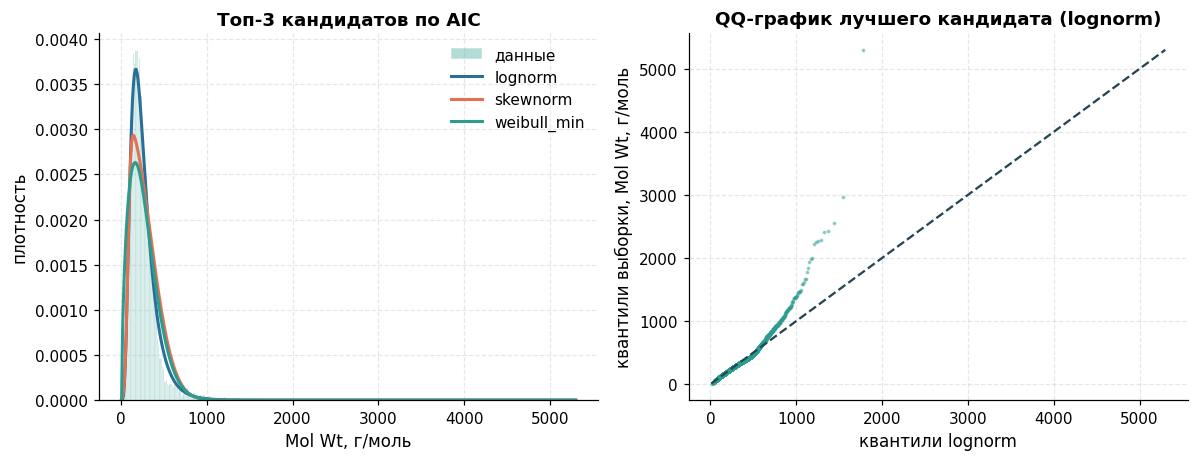

In [ ]:
tab, fitted = lu.fit_candidates(x3, ["lognorm", "gamma", "weibull_min", "norm", "skewnorm"])
display(tab)
lu.plot_fits(x3, fitted, tab, LAB3, C3)

*Замечание:* p-value критерия Колмогорова–Смирнова при параметрах, оценённых по этим же данным, формально
некорректно (нужна поправка Лиллиефорса или параметрический бутстрап), поэтому здесь KS D используется
как мера расхождения, а выбор опирается на AIC/BIC и QQ-график.

Лучший кандидат Логнормальное.

**3.2.3 Математическая база распределения**

## 3.2.3 Математическая база распределения

**Выбранные кандидаты:** логнормальное распределение (однокомпонентное) и **смесь логнормальных** распределений (K = 3 компоненты). Именно они лучше всего описывают Mol Wt: правая асимметрия ≈ 5.5, тяжёлый правый хвост (максимум ≈ 5300 г/моль), одна выраженная мода в районе малых молекул и «плечо» в сторону крупных.

---

### 1. Плотность, функция распределения, носитель, смысл параметров

**Логнормальное распределение** $\mathrm{LogN}(\mu, \sigma^2)$ определяется так: если $Y = \ln X \sim \mathcal{N}(\mu, \sigma^2)$, то $X$ имеет логнормальное распределение.

- **Носитель:** $x \in (0, +\infty)$ — молекулярная масса строго положительна.
- **Плотность:**
$$
f(x; \mu, \sigma) = \frac{1}{x\,\sigma\sqrt{2\pi}} \exp\!\left(-\frac{(\ln x - \mu)^2}{2\sigma^2}\right), \quad x > 0.
$$
Множитель $1/x$ — это якобиан замены $y = \ln x$.

- **Функция распределения:**
$$
F(x; \mu, \sigma) = \Phi\!\left(\frac{\ln x - \mu}{\sigma}\right),
$$
где $\Phi$ — стандартная нормальная ФР.

- **Смысл параметров:** $\mu$ — это матожидание $\ln X$ (сдвиг в логарифмической шкале, «типичный порядок массы»), $\sigma$ — стандартное отклонение $\ln X$ (разброс в логарифмической шкале, мера гетерогенности датасета по размеру молекул).

**Смесь логнормальных** с $K$ компонентами:
$$
f(x) = \sum_{k=1}^{K} w_k \, f_{\mathrm{LogN}}(x; \mu_k, \sigma_k), \quad w_k > 0,\ \sum_k w_k = 1.
$$
Каждая компонента описывает свой класс соединений (например: малые органические молекулы, средние фармацевтические, крупные полимеры/биомолекулы). В нашем случае $K = 3$.

---

### 2. Матожидание, дисперсия, асимметрия

Для одной логнормальной компоненты:

$$
\mathbb{E}[X] = \exp\!\left(\mu + \frac{\sigma^2}{2}\right),
$$

$$
\mathrm{Var}(X) = \bigl(e^{\sigma^2} - 1\bigr)\, e^{2\mu + \sigma^2},
$$

$$
\gamma_1 = \bigl(e^{\sigma^2} + 2\bigr)\sqrt{e^{\sigma^2} - 1}.
$$

**Важно:** асимметрия зависит **только от $\sigma$** и всегда положительна. При $\sigma \to 0$ распределение стремится к вырожденному (симметричному), при росте $\sigma$ асимметрия быстро растёт — это и объясняет наблюдаемое значение $\approx 5.5$.

Для смеси моменты считаются по формуле полной вероятности:
$$
\mathbb{E}[X] = \sum_k w_k \, \mathbb{E}[X_k], \quad \mathbb{E}[X^2] = \sum_k w_k \, \mathbb{E}[X_k^2],
$$
и далее $\mathrm{Var}(X) = \mathbb{E}[X^2] - (\mathbb{E}[X])^2$. Асимметрия смеси не имеет простой замкнутой формы и вычисляется через центральный момент третьего порядка.

---

### 3. Оценка параметров (MLE)

Параметры $(\mu, \sigma)$ логнормального распределения оцениваются методом максимального правдоподобия. Логарифм правдоподобия для выборки $x_1, \dots, x_n$:

$$
\ell(\mu, \sigma) = \sum_{i=1}^{n} \ln f(x_i; \mu, \sigma) = -n\ln\sigma - \frac{n}{2}\ln(2\pi) - \sum_{i=1}^{n} \ln x_i - \frac{1}{2\sigma^2}\sum_{i=1}^{n}(\ln x_i - \mu)^2.
$$

**Что максимизируется:** $\ell(\mu, \sigma)$ по $(\mu, \sigma)$. Дифференцируя, получаем явные решения:
$$
\hat\mu = \frac{1}{n}\sum_{i=1}^{n} \ln x_i, \qquad \hat\sigma^2 = \frac{1}{n}\sum_{i=1}^{n}(\ln x_i - \hat\mu)^2.
$$
То есть MLE для логнормального — это просто выборочное среднее и выборочная дисперсия логарифмов данных.

Для **смеси** параметров $(w_k, \mu_k, \sigma_k)_{k=1}^K$ явного решения нет — используется **EM-алгоритм** (Dempster, Laird, Rubin, 1977). На E-шаге вычисляются «ответственности» $\gamma_{ik} = P(\text{компонента } k \mid x_i)$, на M-шаге пересчитываются $w_k, \mu_k, \sigma_k$ как взвешенные MLE. Правдоподобие на каждой итерации не убывает. Число компонент $K = 3$ выбрано по компромиссу BIC и KS-критерия: при $K \geq 3$ KS D уже ниже критического значения, а дальнейшее увеличение $K$ даёт мизерный выигрыш при росте числа параметров.

---

### 4. Откуда берётся такое распределение

Логнормальное распределение возникает там, где величина формируется как **произведение многих независимых положительных множителей** (мультипликативный эффект). Молекулярная масса — это сумма атомных масс, но если рассматривать *отношение* масс разных молекул или *вклад* каждого атома в логарифмической шкале, то $\ln M = \sum_i \ln m_i + \ln(\text{число атомов})$. По **ЦПТ**, сумма многих независимых слагаемых (вкладов атомов/фрагментов) стремится к нормальному распределению, откуда $M = e^{\ln M}$ — логнормальна.

Альтернативное объяснение: **геометрическое броуновское движение** размера молекулы при «росте» (добавлении фрагментов) в химическом пространстве даёт логнормальное стационарное распределение.

Смесь логнормальных возникает, когда в датасете **несколько качественно разных классов** соединений (малые органики, лекарства, пептиды, полимеры), каждый со своим типичным диапазоном масс.

---

### 5. Особенности

- **Тяжесть хвостов:** правый хвост логнормального тяжелее нормального, но легче степенного (Pareto). $\mathbb{P}(X > x) \sim \frac{\sigma}{\ln x}\,\varphi\!\left(\frac{\ln x - \mu}{\sigma}\right)$ при $x \to \infty$ — убывает медленнее экспоненты. Это согласуется с наличием в датасете единичных очень крупных молекул (до 5300 г/моль).
- **Ограниченность:** носитель $(0, +\infty)$ — нижняя граница 0 естественна (масса не может быть отрицательной или нулевой для реального соединения). Верхней границы нет, что тоже химически осмысленно.
- **Связь с другими распределениями:**
  - Если $X \sim \mathrm{LogN}(\mu, \sigma^2)$, то $\ln X \sim \mathcal{N}(\mu, \sigma^2)$.
  - При $\sigma \to 0$ логнормальное вырождается в точечное распределение в $e^\mu$.
  - Логнормальное — частный случай **двупараметрического семейства Box–Cox** при $\lambda = 0$.
  - Смесь логнормальных в логарифмической шкале превращается в **смесь нормальных** — отсюда удобство подбора: сначала берём $\ln x_i$, затем применяем обычный Gaussian Mixture Model.

---

### 6. Почему это логично для химической природы Mol Wt

Молекулярная масса в датасете AqSolDB — это **расчётная величина** (по формуле соединения), то есть для конкретной молекулы она детерминирована. Случайность — в том, *какая молекула* попала в выборку из химического пространства. Химическое пространство устроено иерархически: подавляющее большинство известных соединений — малые органические молекулы (100–500 г/моль, «правило пяти» Липинского), затем идёт длинный «хвост» из более крупных веществ (природные продукты, пептиды, полимеры, координационные соединения). Такая структура **естественным образом даёт правую асимметрию** и тяжёлый хвост, которые логнормальное распределение (и его смеси) описывает лучше, чем симметричное нормальное или ограниченное бета-распределение.

Однокомпонентное логнормальное хорошо описывает «ядро» распределения (малые и средние молекулы), но систематически недооценивает правый хвост — отсюда необходимость смеси из $K = 3$ компонент, где третья компонента с большим $\mu_k$ и $\sigma_k$ как раз отвечает за редкие крупные молекулы.

---

**Источники:** Limpert et al. *Log-normal distributions across the sciences* (Bioscience, 2001); Aitchison & Brown *The Lognormal Distribution* (Cambridge UP, 1957); Dempster, Laird, Rubin *Maximum likelihood from incomplete data via the EM algorithm* (JRSS B, 1977); Кнут, т. 2, гл. 3 (по общему контексту генерации).

<a id="rv3-ind"></a>

### 3.3 Independence & Estimations

[↑ к оглавлению](#toc)

**3.3.1 Независимость**

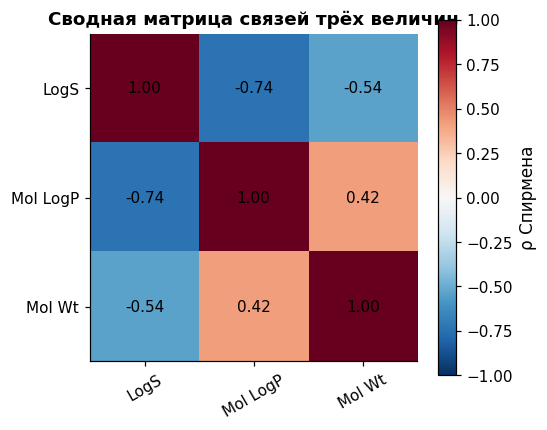

In [ ]:
sub = pd.DataFrame({"LogS": df[cols["logS"]], "Mol LogP": df[cols["logP"]], "Mol Wt": df[cols["molwt"]]}).apply(
    pd.to_numeric, errors="coerce").dropna()
corr = sub.corr(method="spearman")
fig, ax = plt.subplots(figsize=(4.8, 4.2))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(3), corr.columns, rotation=30)
ax.set_yticks(range(3), corr.columns)
ax.grid(False)
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")
fig.colorbar(im, label="ρ Спирмена")
ax.set_title("Сводная матрица связей трёх величин")
plt.show()

Mol Wt сильно положительно коррелирует с LogP (крупные молекулы часто более гидрофобны) и отрицательно с LogS (крупные молекулы хуже растворяются). Это полностью согласуется с химической интуицией.

**3.3.2 Состоятельность оценок (эмпирически)**

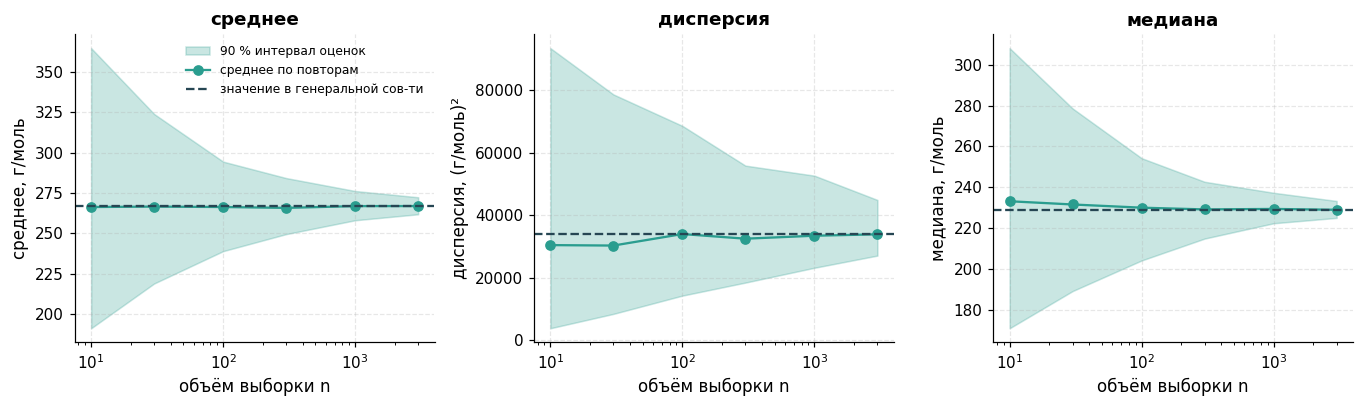

,n,среднее оценок,разброс оценок (ст. откл.)
0,10,266.2,56.12
3,30,266.5,35.18
6,100,266.2,18.11
9,300,265.7,10.45
12,1000,266.8,5.528
15,3000,266.8,3.169


In [ ]:
N = len(x3)
ns = [n_ for n_ in (10, 30, 100, 300, 1000, 3000) if n_ <= N // 2]
tab_c = lu.consistency(x3, ns, reps=300, replace=True)
lu.plot_consistency(tab_c, lu.true_values(x3), UNIT3, C3)
display(tab_c.query("оценка == 'среднее'")[["n", "mean", "std"]].rename(
    columns={"mean": "среднее оценок", "std": "разброс оценок (ст. откл.)"}))

**3.3.3 Выборка из генеральной совокупности: с возвращением и без**

,схема,E[x̄],Var(x̄) эмпирич.,Var(x̄) теория,E[s²],E[медиана]
0,генеральная совокупность,266.7,NaN,NaN,3.392e+04,228.7
1,с возвращением,266.5,17.11,16.99,3.391e+04,229
2,без возвращения,266.7,13.26,13.6,3.404e+04,229.1


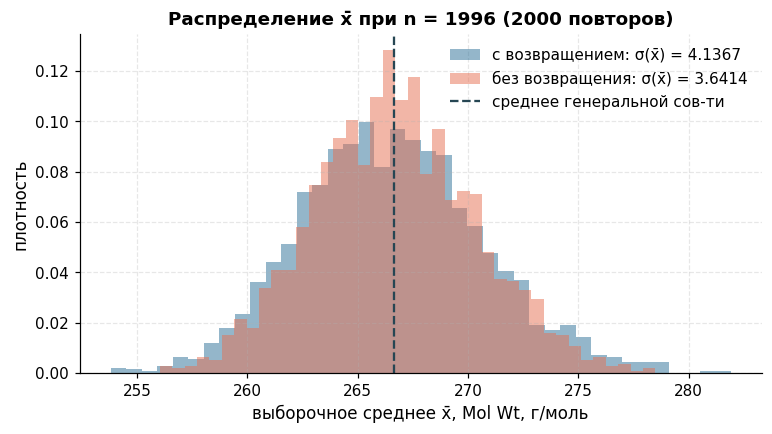

In [ ]:
N = len(x3)
n_s = N // 5
display(lu.sampling_comparison(x3, n_s))
lu.plot_sampling_means(x3, n_s, LAB3)

> ✍️ **ЗАПОЛНИ САМА** (своими словами, потом удали эту подсказку)
>
> Генеральная совокупность = весь датасет (N соединений), выборка — n = N/5.
> - Чем отличаются схемы с возвращением и без; какая подходит для конечной ГС и почему.
> - Выведи сама поправку на конечность: $\mathrm{Var}(\bar X)=\frac{\sigma^2}{n}\cdot\frac{N-n}{N-1}$ (без возвращения).
> - Совпала ли теория с эмпирикой в таблице? Совпали ли статистики выборки и ГС?
> - Вывод: насколько выборка такого объёма позволяет судить о генеральной совокупности.

<a id="rv3-hyp"></a>

### 3.4 Hypothesis

[↑ к оглавлению](#toc)

**Гипотеза (предложена, можешь заменить):** распределение молекулярной массы одинаково во всех группах надёжности
G1–G5 (т.е. «качество» данных не связано с размером молекулы).

,показатель,значение,p-value
0,n / медиана в группе G1,7746 / 237.255,NaN
1,n / медиана в группе G2,235 / 284.428,NaN
2,n / медиана в группе G3,1182 / 200.250,NaN
3,n / медиана в группе G4,183 / 227.076,NaN
4,n / медиана в группе G5,636 / 171.712,NaN
5,Краскел–Уоллис H,292.4,4.777e-62


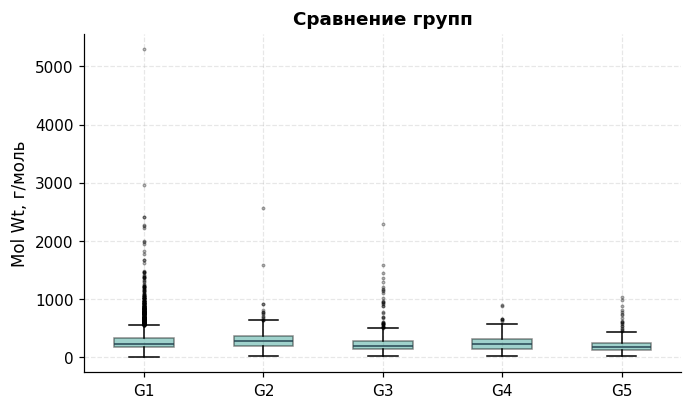

In [ ]:
if cols["group"]:
    gcol = df[cols["group"]]
    m = pd.to_numeric(df[cols["molwt"]], errors="coerce")
    groups = {str(k): m[gcol == k].dropna().to_numpy() for k in sorted(gcol.dropna().unique(), key=str)}
    groups = {k: v for k, v in groups.items() if len(v) >= 5}
    display(lu.kruskal_report(groups))
    lu.plot_groups(groups, LAB3, C3)
else:
    print("Колонка Group не найдена — выбери другую гипотезу.")

> ✍️ **ЗАПОЛНИ САМА** (своими словами, потом удали эту подсказку)
>
> $H_0$ / $H_1$, $\alpha$, почему Краскел–Уоллис, результат, почему при большом n возможна «значимость без практического смысла»
> (посмотри на разницу медиан), химическая интерпретация (почему в группы с большим числом источников могут попадать
> более простые/известные молекулы).

<a id="rv3-res"></a>

### 3.5 Вывод по величине 03

[↑ к оглавлению](#toc)

> ✍️ **ЗАПОЛНИ САМА** (своими словами, потом удали эту подсказку)
>
> Итоги по Mol Wt — как в 1.5.

<a id="resume"></a>

## 4. Lab resume

[↑ к оглавлению](#toc)

> ✍️ **ЗАПОЛНИ САМА** (своими словами, потом удали эту подсказку)
>
> Общий вывод по спринту 1: как три величины различаются по природе и по распределению, какие проверенные гипотезы
> что говорят о датасете (растворимость соединений в целом), что получилось/не получилось и что пойдёт в генератор (спринт 2).

<a id="mark-table"></a>

### 4.1 cat_mark_table

[↑ к оглавлению](#toc)

> ✍️ Заполни `cat_id` и `coeff` по таблице категорий преподавателя; в `comment` укажи, где в ноутбуке это сделано.
> Критерии оценивания, которые ты считаешь выполненными, перечисли именно здесь.

| cat_id | notebook_link | coeff | comment |
|--------|---------------|-------|---------|
|  | [1.1.1](#rv1-desc), [2.1.1](#rv2-desc), [3.1.1](#rv3-desc) |  | Три случайные величины, обоснование стохастичности |
|  | [1.3.1](#rv1-ind), [2.3.1](#rv2-ind), [3.3.1](#rv3-ind) |  | Независимость пар величин (Пирсон, Спирмен, Кендалл, χ², MI) |
|  | [1.3.2](#rv1-ind), [2.3.2](#rv2-ind), [3.3.2](#rv3-ind) |  | Эмпирическая состоятельность оценок |
|  | [1.2](#rv1-eda), [2.2](#rv2-eda), [3.2](#rv3-eda) |  | EDA, нормализация, подбор распределения |
|  | [1.3.3](#rv1-ind), [2.3.3](#rv2-ind), [3.3.3](#rv3-ind) |  | Выборка с возвращением и без, сравнение с ГС |
|  | [1.2.3](#rv1-eda), [2.2.3](#rv2-eda), [3.2.3](#rv3-eda) |  | Математическая база распределений |
|  | [1.4](#rv1-hyp), [2.4](#rv2-hyp), [3.4](#rv3-hyp) |  | Проверка гипотез (по одной на величину) |
|  | [список литературы](#refs) |  | Литература |
|  |  |  | Единая стилистика графиков, единицы измерения, LaTeX, оглавление и якоря, скрытие кода (КТвД) |

<a id="refs"></a>

## 5. Список литературы

[↑ к оглавлению](#toc)

> ✍️ **ЗАПОЛНИ САМА** (своими словами, потом удали эту подсказку)
>
> Оформи по ГОСТ или единообразно. Обязательно: статья про датасет (Sorkun et al., 2019). Добавь книги и статьи по
> своим распределениям и методам (по заданию +балл за подбор литературы в библиотеках и базах: РГБ, РНБ, ИТМО, IEEE,
> ResearchGate и т.д.). Ссылайся на источники по тексту.

1. Sorkun M. C., Khetan A., Er S. AqSolDB, a curated reference set of aqueous solubility and 2D descriptors for a diverse
   set of compounds // Scientific Data. 2019. Vol. 6. Art. 143. doi:10.1038/s41597-019-0151-1.
2. ✍️ …

<a id="lab01-s2"></a>

# Lab01 - sprint 2

**Что сделано.** Генератор случайных чисел на основе распределений из спринта 1. Основная величина: LogS (random 01). Дополнительные распределения (+балл за каждое): Mol LogP (random 02) и Mol Wt (random 03). Все выборки порождаются кодом пакета `lab01.generators` поверх собственных датчиков U[0,1) (ЛКГ, Вихрь Мерсенна); `numpy.random` и `scipy.stats.*.rvs` не используются. `scipy` нужен только для оценки параметров (MLE, как в спринте 1) и для статистических критериев.

> **Как запускать.** Раздел выполняется после спринта 1 (использует его данные и переменные), поэтому запускай ноутбук целиком: *Restart & Run All*.

In [ ]:
import sys, inspect
sys.path.insert(0, "src")          # пакет lab01 лежит в src/

from lab01 import report
from lab01.generators import LCG, MT19937, REGISTRY, make_sampler, continuous, mixture, quantile
from lab01.generators.uniform import hull_dobell
from lab01.pipeline import run_rv, select_k, ks_crit

N_GEN, SEED = 20_000, 2024

def ks_fit(x, dist, params):
    """Одновыборочный KS против подобранного scipy-распределения (через frozen cdf: устойчиво между версиями SciPy)."""
    return stats.kstest(x, getattr(stats, dist)(*params).cdf)

def show_source(*objs):
    """Показывает исходный код функций пакета (сам код лежит в src/lab01/generators)."""
    display(Markdown("```python\n" + "\n\n".join(inspect.getsource(o) for o in objs) + "\n```"))

display(Markdown(f"Данные и переменные `x1, x2, x3` взяты из спринта 1 ({len(x1)} соединений). "
                 f"Критическое D одновыборочного KS (5 %, n={len(x1)}): **{ks_crit(len(x1)):.4f}**."))

Данные и переменные `x1, x2, x3` взяты из спринта 1 (9982 соединений). Критическое D одновыборочного KS (5 %, n=9982): **0.0136**.

<a id="base"></a>

## 6. Базовые датчики U(0,1)

[↑ к оглавлению](#toc)

> ✍️ **ЗАПОЛНИ САМА** (своими словами, потом удали эту подсказку)
>
> - Зачем нужен равномерный датчик: все остальные методы получают на вход $U\sim U[0,1)$ и преобразуют его.
> - ЛКГ: $X_{n+1}=(aX_n+c)\bmod m$. Теорема Халла–Добелла: **выпиши три условия и объясни своими словами, что ломается без каждого** (разбери маленький пример, например $m=16$).
> - Вихрь Мерсенна: период $2^{19937}-1$, идея линейной рекуррентности над $\mathbb{F}_2$, зачем нужен tempering (маски и сдвиги в `next_int32`).
> - Тесты Кнута: что проверяет каждый (χ², KS, серийный, промежутков, серий, последовательная корреляция), что значит «p-value слишком маленький» и «слишком близкий к 1».
> - Честно укажи упрощение: тест серий реализован по нормальному приближению числа возрастающих серий, а не полным тестом Кнута.

,"LCG, m=2^32 (a=1664525, c=1013904223)",MT19937,"LCG, m=2^11 (учебный плохой пример)"
"p-value, n = 200000",,,
chi2_uniform,0.8641,0.9879,0.0853
ks,0.613,0.9438,1
serial_pairs,0.3052,0.2878,0
gap,0.8781,0.8484,0
runs_up,0.8983,0.9722,0.4317
serial_corr,0.6882,0.3057,0


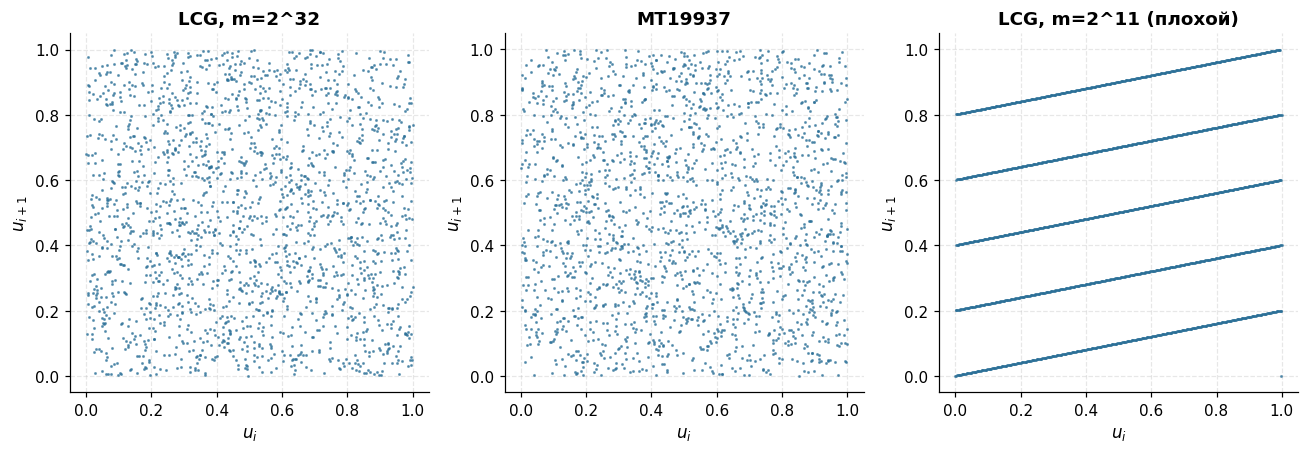

In [ ]:
display(report.uniform_battery_table())
report.plot_uniform_pairs()

**Реализации** (код лежит в `src/lab01/generators/uniform.py`):

In [ ]:
show_source(hull_dobell, LCG)

```python
def hull_dobell(a: int, c: int, m: int) -> bool:
    """Условия теоремы Халла-Добелла: период ЛКГ равен m при любом seed.

    1) gcd(c, m) = 1
    2) a - 1 делится на каждый простой делитель m
    3) если m делится на 4, то и a - 1 делится на 4

    TODO(автор): опиши своими словами, почему без каждого из трёх условий
    последовательность зацикливается раньше, чем через m шагов
    (разбери на маленьком примере, например m = 16).
    """
    from math import gcd

    if gcd(c, m) != 1:
        return False
    if any((a - 1) % p != 0 for p in prime_factors(m)):
        return False
    if m % 4 == 0 and (a - 1) % 4 != 0:
        return False
    return True


class LCG:
    """Линейный конгруэнтный датчик.

    Параметры по умолчанию (a=1664525, c=1013904223, m=2^32) часто приводятся в
    литературе (в т.ч. в Numerical Recipes); условия Халла-Добелла для них
    проверяются в конструкторе, а не принимаются на веру.
    """

    def __init__(self, seed: int = 12345, a: int = 1664525,
                 c: int = 1013904223, m: int = 2**32, check: bool = True):
        if check and not hull_dobell(a, c, m):
            raise ValueError(f"Параметры a={a}, c={c}, m={m} не дают полный период")
        self.a, self.c, self.m = a, c, m
        self.state = seed % m

    def next_int(self) -> int:
        self.state = (self.a * self.state + self.c) % self.m
        return self.state

    def random(self) -> float:
        return self.next_int() / self.m

    def random_array(self, n: int) -> np.ndarray:
        out = np.empty(n)
        for i in range(n):
            out[i] = self.next_int() / self.m
        return out

```

**Эффективность нормальных датчиков** (теория: полярный метод принимает $\pi/4\approx0{,}785$ точек, метод отношений около $0{,}731$):

In [ ]:
display(report.normal_methods_table())

,метод,доля принятых: эксперимент,доля принятых: теория,равномерных на 1 значение: эксперимент,равномерных на 1 значение: теория,"время, мс на 10⁴ значений","KS D vs N(0,1)",KS p
0,полярный (Марсалья),0.7816,0.7854,1.279,1.273,49.78,0.005753,0.07279
1,отношений (Киндерман–Монахан),0.7298,0.7306,2.741,2.738,85.66,0.002586,0.8907
2,Бокс–Мюллер,1,1,1,1,22.86,0.003045,0.7416


> ✍️ **ЗАПОЛНИ САМА** (своими словами, потом удали эту подсказку)
>
> Интерпретация обеих таблиц: какой датчик берём как основной (MT19937) и почему; чем плох учебный ЛКГ с $m=2^{11}$ (решётка на графике, провал серийного теста); сколько равномерных чисел тратит каждый нормальный датчик.

<a id="r1"></a>

## 7. random 01 — LogS (основная величина)

[↑ к оглавлению](#toc)

<a id="r1-desc"></a>

### 7.1 Description

[↑ к оглавлению](#toc)

> ✍️ **ЗАПОЛНИ САМА** (своими словами, потом удали эту подсказку)
>
> Коротко (подробности в спринте 1): что за величина, единицы, природа случайности. Почему именно её распределение берём под генератор: асимметрия $\approx -0{,}55$, левый хвост, один одиночный закон не проходит критерий согласия (см. 7.4).

<a id="r1-math"></a>

### 7.2 math desc

[↑ к оглавлению](#toc)

> ✍️ **ЗАПОЛНИ САМА** (своими словами, потом удали эту подсказку)
>
> Выведи **сама** (фото рукописных выкладок тоже подойдёт):
> 1. **Полярный метод Марсальи.** Почему $S=V_1^2+V_2^2\sim U(0,1)$ в единичном круге и не зависит от угла (замена на полярные координаты, якобиан); почему $Z_i=V_i\sqrt{-2\ln S/S}$ стандартно нормальны; вероятность принятия $\pi/4$.
> 2. **Skew-normal (Azzalini).** Плотность $2\varphi(z)\Phi(az)$; почему $\delta|Z_0|+\sqrt{1-\delta^2}Z_1$ имеет такую плотность; как $a$ управляет асимметрией; почему при $a\to\pm\infty$ получается полунормальное.
> 3. **Суперпозиция (смесь).** Плотность $f(x)=\sum_j w_j\,\mathcal N(x;\mu_j,\sigma_j^2)$; почему «выбрать компоненту по $U$, затем нормальное из неё» даёт именно эту плотность (формула полной вероятности).
> 4. **EM-алгоритм.** Выведи E- и M-шаги для смеси нормальных из лог-правдоподобия; почему правдоподобие не убывает.
> 5. **Квантильное преобразование.** $F^{-1}(U)\sim F$; что теряется при линейной интерполяции между порядковыми статистиками и почему этот датчик по построению не выдаёт значений вне $[\min,\max]$.
> 6. **Выбор числа компонент.** AIC/BIC: формулы, чем различается штраф, почему KS-критерий здесь тоже нужен.

<a id="r1-code"></a>

### 7.3 code

[↑ к оглавлению](#toc)

In [ ]:
single1 = ["norm", "skewnorm", "johnsonsu"]
tab1, fitted1 = lu.fit_candidates(x1, single1)
display(report.methods_table([n for n in single1 if n in fitted1], fitted1))

,распределение,"параметры (MLE, порядок scipy)",метод генерации,источник
0,norm,"loc=-2.89, scale=2.368",полярный метод Марсальи + X = loc + scale*Z,"Кнут т.2, 3.4.1, алг. P"
1,skewnorm,"a=-3.101, loc=-0.09105, scale=3.666",композиция двух нормальных (Azzalini): delta|Z...,"Azzalini, 1985"
2,johnsonsu,"a=10.49, b=3.921, loc=6.282, scale=1.23",нормальное + преобразование sinh: loc + scale*...,"Johnson, 1949"


**Выбор числа компонент смеси** (`KS D` одновыборочный; сравнивай с критическим значением выше):

In [ ]:
sel1 = pd.DataFrame(select_k(x1))
display(sel1)
K1 = 3   # ✍️ выбери и обоснуй: KS проходит уже при k = 3, BIC продолжает улучшаться при больших k

,k,AIC,BIC,KS D
0,1,4.554e+04,4.556e+04,0.0538
1,2,4.483e+04,4.486e+04,0.01899
2,3,4.447e+04,4.453e+04,0.009229
3,4,4.44e+04,4.448e+04,0.006565
4,5,4.437e+04,4.447e+04,0.004662


**Реализации** (код в `src/lab01/generators/`):

In [ ]:
show_source(continuous.skewnorm, mixture.fit_gmm, mixture.sample_mixture, quantile.EmpiricalQuantile)

```python
def skewnorm(rng, n: int, a: float, loc: float = 0.0, scale: float = 1.0) -> np.ndarray:
    """Асимметричное нормальное (Azzalini): delta = a / sqrt(1 + a^2),
    X = delta |Z0| + sqrt(1 - delta^2) Z1 с независимыми Z0, Z1 ~ N(0,1).

    TODO(автор): докажи, что плотность этой величины 2 phi(x) Phi(a x)
    (условие: Z1-часть берётся при положительном Z0-условии), и объясни,
    чем параметр a управляет.
    """
    delta = a / math.sqrt(1.0 + a * a)
    z0 = np.abs(standard_normal(rng, n))
    z1 = standard_normal(rng, n)
    return loc + scale * (delta * z0 + math.sqrt(1.0 - delta * delta) * z1)


def fit_gmm(x: np.ndarray, k: int = 2, max_iter: int = 5000, tol: float = 1e-10) -> dict:
    """ЕМ для смеси k нормальных. Возвращает словарь w, mu, sd, loglik, n_iter.

    Компоненты упорядочены по mu. Начальные центры берутся из квантилей, чтобы
    результат не зависел от случайности (воспроизводимость).
    """
    x = np.asarray(x, dtype=float)
    n = len(x)
    w = np.full(k, 1.0 / k)
    mu = np.quantile(x, (np.arange(k) + 0.5) / k)
    sd = np.full(k, x.std())
    prev = -np.inf
    n_iter = 0
    for n_iter in range(1, max_iter + 1):
        # E-шаг: ответственности r[j, i] = P(компонента j | x_i)
        logp = np.stack([
            np.log(w[j]) - np.log(sd[j]) - 0.5 * np.log(2 * np.pi)
            - 0.5 * ((x - mu[j]) / sd[j]) ** 2
            for j in range(k)
        ])
        m = logp.max(axis=0)
        lse = m + np.log(np.exp(logp - m).sum(axis=0))
        r = np.exp(logp - lse)
        loglik = float(lse.sum())
        # M-шаг
        nk = np.maximum(r.sum(axis=1), 1e-12)
        w = nk / n
        mu = (r * x).sum(axis=1) / nk
        sd = np.maximum(np.sqrt((r * (x - mu[:, None]) ** 2).sum(axis=1) / nk), 1e-6)
        if abs(loglik - prev) < tol * n:
            break
        prev = loglik
    order = np.argsort(mu)
    return {"w": w[order], "mu": mu[order], "sd": sd[order],
            "loglik": loglik, "n_iter": n_iter, "k": k}


def sample_mixture(params: dict, n: int, rng, normal_sampler=polar_marsaglia
                   ) -> np.ndarray:
    """Метод композиции: номер компоненты по равномерному u (сравнение с
    накопленными весами), затем значение через Z ~ N(0,1)."""
    z, _ = normal_sampler(rng, n)
    u = rng.random_array(n)
    cum = np.cumsum(params["w"])
    cum[-1] = 1.0
    comp = np.searchsorted(cum, u, side="right")
    return params["mu"][comp] + params["sd"][comp] * z


class EmpiricalQuantile:
    def __init__(self, data: np.ndarray):
        self.x = np.sort(np.asarray(data, dtype=float))
        self.n = len(self.x)

    def ppf(self, u: np.ndarray) -> np.ndarray:
        pos = np.asarray(u) * (self.n - 1)
        lo = np.floor(pos).astype(int)
        hi = np.minimum(lo + 1, self.n - 1)
        frac = pos - lo
        return self.x[lo] * (1.0 - frac) + self.x[hi] * frac

    def sample(self, n: int, rng) -> np.ndarray:
        return self.ppf(rng.random_array(n))

```

<a id="r1-tests"></a>

### 7.4 tests

[↑ к оглавлению](#toc)

,mean,std,skew,excess_kurt,q01,q05,q25,q50,q75,q95,q99,ks_stat,ks_p,wasserstein,W/σ
генератор,,,,,,,,,,,,,,,
real,-2.89,2.368,-0.5516,-0.06,-8.831,-7.43,-4.326,-2.618,-1.21,0.64,1.107,NaN,NaN,NaN,NaN
normal (polar),-2.877,2.383,-0.001741,-0.05857,-8.436,-6.792,-4.488,-2.886,-1.258,1.085,2.562,0.05515,4.773e-18,0.2608,0.1101
skew-normal (Azzalini),-2.871,2.385,-0.6587,0.5049,-9.447,-7.285,-4.313,-2.565,-1.145,0.4918,1.502,0.0205,0.007312,0.09168,0.03871
mixture k=3 (superposition),-2.869,2.354,-0.5309,-0.01003,-8.933,-7.247,-4.282,-2.582,-1.227,0.6504,1.211,0.01112,0.3802,0.04622,0.01952
empirical quantile (inverse ECDF),-2.905,2.393,-0.5347,-0.1161,-8.815,-7.461,-4.36,-2.626,-1.22,0.6775,1.12,0.005683,0.9817,0.02664,0.01125


,|Δ среднее| / σ,|Δ σ| / σ,|Δ асимметрия|,|Δ эксцесс|,KS D,все метрики в допуске
генератор,,,,,,
normal (polar),0.00544 ✓,0.00613 ✓,0.55 ✗,0.00143 ✓,0.0552 ✗,False
skew-normal (Azzalini),0.00802 ✓,0.00719 ✓,0.107 ✓,0.565 ✗,0.0205 ✓,False
mixture k=3 (superposition),0.00899 ✓,0.00599 ✓,0.0207 ✓,0.05 ✓,0.0111 ✓,True
empirical quantile (inverse ECDF),0.0064 ✓,0.0103 ✓,0.0169 ✓,0.0561 ✓,0.00568 ✓,True


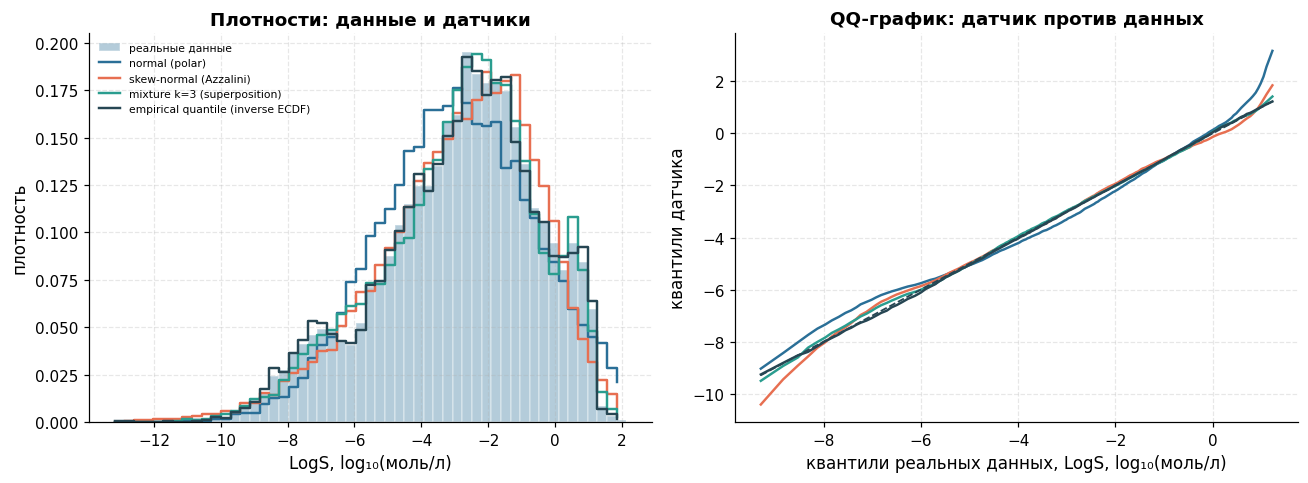

In [ ]:
_, samples1, info1 = run_rv("LogS", x1, n=N_GEN, seed=SEED, k_mix=K1)
display(report.generator_table(x1, samples1))
display(report.match_verdict(x1, samples1))
report.plot_generator_comparison(x1, samples1, LAB1, C1)

**Одновыборочный KS: одиночное семейство против смеси** (по параметрам, подобранным на тех же данных; значения ниже критического не отвергаются):

In [ ]:
crit1 = ks_crit(len(x1))
display(pd.DataFrame({"KS D": {
    "normal (MLE)": ks_fit(x1, "norm", fitted1["norm"]).statistic,
    "skew-normal (MLE)": ks_fit(x1, "skewnorm", fitted1["skewnorm"]).statistic,
    f"смесь k={K1}": stats.kstest(x1, mixture.mixture_cdf(info1["gmm"])).statistic,
    "критическое D (5 %)": crit1}}))
display(pd.DataFrame({"вес": info1["gmm"]["w"], "μ": info1["gmm"]["mu"], "σ": info1["gmm"]["sd"]}).rename_axis("компонента"))
display(pd.Series(report.reproducibility_check(make_sampler("skewnorm", fitted1["skewnorm"]))).to_frame("результат"))

,KS D
normal (MLE),0.0538
skew-normal (MLE),0.0204
смесь k=3,0.009229
критическое D (5 %),0.01359


,вес,μ,σ
компонента,,,
0,0.3272,-5.235,2.028
1,0.6087,-2.005,1.383
2,0.0641,0.6764,0.3425


,результат
тот же seed: идентично,True
другой seed: отличается,True


> ✍️ **ЗАПОЛНИ САМА** (своими словами, потом удали эту подсказку)
>
> Интерпретация: какие датчики совпали с данными по метрикам и KS, а какие нет и почему (чем смесь лучше одиночного skew-normal). Обязательно:
> - квантильный датчик «проходит» почти идеально, потому что он пересэмплирует сами данные: это не доказательство модели;
> - параметры подобраны на тех же данных, поэтому p-value слегка оптимистичны;
> - чему соответствуют допуски в `report.TOLERANCES` и почему выбраны именно такие.
> Не приписывай компонентам смеси химического смысла: это гибкое приближение, а не разложение по классам соединений.

<a id="r1-res"></a>

### 7.5 resume

[↑ к оглавлению](#toc)

> ✍️ **ЗАПОЛНИ САМА** (своими словами, потом удали эту подсказку)
>
> Итог по random 01: какой метод выбран основным, что совпало/не совпало, ограничения (диапазон значений, хвосты), скорость датчиков (см. `info1['timing_s']`).

<a id="r2"></a>

## 8. random 02 — Mol LogP (дополнительное распределение)

[↑ к оглавлению](#toc)

<a id="r2-desc"></a>

### 8.1 Description

[↑ к оглавлению](#toc)

> ✍️ **ЗАПОЛНИ САМА** (своими словами, потом удали эту подсказку)
>
> Что такое Mol LogP, единицы, откуда случайность (расчётная величина RDKit: подумай, как это согласуется с доказательством стохастичности из спринта 1). Тяжёлые хвосты: эксцесс $\approx 29{,}5$, выбросы от $-41$ до $68$.

<a id="r2-math"></a>

### 8.2 math desc

[↑ к оглавлению](#toc)

> ✍️ **ЗАПОЛНИ САМА** (своими словами, потом удали эту подсказку)
>
> Выведи **сама**:
> 1. **Student $t_\nu$** как $Z/\sqrt{\chi^2_\nu/\nu}$: плотность, откуда тяжёлые хвосты; при каких $\nu$ существуют среднее, дисперсия и эксцесс (для $\nu\approx 2{,}4$ эксцесса **нет**: что это значит для сравнения выборочных моментов ниже).
> 2. **Гамма-датчик Марсальи–Цанга**: $\chi^2_\nu=2\,\mathrm{Gamma}(\nu/2)$; почему куб нормального приближает гамма-плотность, откуда условие принятия $\ln U<x^2/2+d(1-v+\ln v)$ и быстрая проверка; буст $U^{1/a}$ при $a<1$ (метод Неймана).

<a id="r2-code"></a>

### 8.3 code

[↑ к оглавлению](#toc)

In [ ]:
single2 = ["norm", "t", "johnsonsu"]
tab2, fitted2 = lu.fit_candidates(x2, single2)
display(report.methods_table([n for n in single2 if n in fitted2], fitted2))

,распределение,"параметры (MLE, порядок scipy)",метод генерации,источник
0,norm,"loc=1.979, scale=3.518",полярный метод Марсальи + X = loc + scale*Z,"Кнут т.2, 3.4.1, алг. P"
1,t,"df=2.401, loc=1.982, scale=1.772","композиция: Z / sqrt(chi2/nu), chi2 = 2*Gamma(...","Кнут т.2, 3.4.1; Marsaglia-Tsang, 2000"
2,johnsonsu,"a=-0.02515, b=0.994, loc=1.925, scale=1.889",нормальное + преобразование sinh: loc + scale*...,"Johnson, 1949"


In [ ]:
show_source(continuous.gamma, continuous.chi2, continuous.student_t)

```python
def gamma(rng, n: int, a: float, loc: float = 0.0, scale: float = 1.0) -> np.ndarray:
    """Gamma(shape=a): метод Марсальи-Цанга для a >= 1; при a < 1 используется
    G(a) = G(a+1) * U^(1/a).

    Для a >= 1: d = a - 1/3, c = 1/sqrt(9d). Пока не принято: x ~ N(0,1),
    v = (1 + c x)^3 (нужно v > 0); принимаем d*v, если
    ln U < x^2/2 + d (1 - v + ln v)  (быстрая проверка: U < 1 - 0.0331 x^4).

    TODO(автор): объясни идею: куб нормального приближает гамма-плотность, а отбор
    Неймана исправляет разницу. Для a<1 выведи U^(1/a) через P(U^(1/a) <= t).
    """
    ns = _NormalStream(rng)
    boost = a < 1.0
    a_eff = a + 1.0 if boost else a
    d = a_eff - 1.0 / 3.0
    c = 1.0 / math.sqrt(9.0 * d)
    out = np.empty(n)
    for i in range(n):
        while True:
            x = ns.next()
            v = 1.0 + c * x
            if v <= 0.0:
                continue
            v = v * v * v
            u = rng.random()
            if u < 1.0 - 0.0331 * x ** 4:
                break
            if u > 0.0 and math.log(u) < 0.5 * x * x + d * (1.0 - v + math.log(v)):
                break
        g = d * v
        if boost:
            u2 = rng.random()
            while u2 == 0.0:
                u2 = rng.random()
            g *= u2 ** (1.0 / a)
        out[i] = g
    return loc + scale * out


def chi2(rng, n: int, df: float) -> np.ndarray:
    """chi^2 с df степенями свободы = 2 * Gamma(df/2)."""
    return 2.0 * gamma(rng, n, a=df / 2.0)


def student_t(rng, n: int, df: float, loc: float = 0.0, scale: float = 1.0) -> np.ndarray:
    """t_nu = Z / sqrt(chi2_nu / nu), Z и chi2_nu независимы (композиция).

    TODO(автор): выведи, почему отношение даёт плотность Стьюдента и откуда
    тяжёлые хвосты при малом nu.
    """
    z = standard_normal(rng, n)
    return loc + scale * z / np.sqrt(chi2(rng, n, df) / df)

```

<a id="r2-tests"></a>

### 8.4 tests

[↑ к оглавлению](#toc)

,mean,std,skew,excess_kurt,q01,q05,q25,q50,q75,q95,q99,ks_stat,ks_p,wasserstein,W/σ
генератор,,,,,,,,,,,,,,,
real,1.979,3.518,0.7182,29.51,-8.99,-2.806,0.6197,1.949,3.419,6.621,11.12,NaN,NaN,NaN,NaN
normal (polar),1.998,3.539,-0.001741,-0.05857,-6.259,-3.818,-0.3943,1.985,4.403,7.884,10.08,0.116,1.633e-78,0.9542,0.2713
Student t (normal/gamma),2.021,3.713,1.002,52,-7.287,-2.641,0.5689,1.981,3.391,6.708,12.32,0.01089,0.4055,0.1318,0.03746
empirical quantile (inverse ECDF),1.984,3.623,1.156,29.66,-8.988,-2.833,0.5944,1.944,3.401,6.746,11.49,0.005683,0.9817,0.053,0.01507


,|Δ среднее| / σ,|Δ σ| / σ,|Δ асимметрия|,|Δ эксцесс|,KS D,все метрики в допуске
генератор,,,,,,
normal (polar),0.00544 ✓,0.00613 ✓,0.72 ✗,29.6 ✗,0.116 ✗,False
Student t (normal/gamma),0.0118 ✓,0.0555 ✗,0.284 ✗,22.5 ✗,0.0109 ✓,False
empirical quantile (inverse ECDF),0.00126 ✓,0.03 ✓,0.437 ✗,0.154 ✓,0.00568 ✓,False


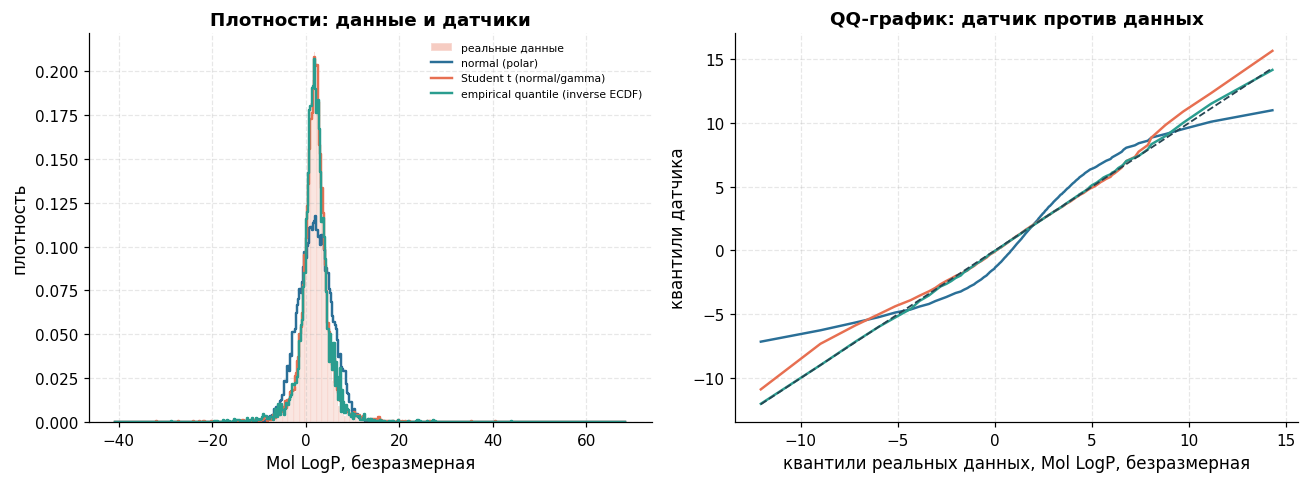

,значение
"KS D (t, MLE)",0.01109
"KS p (t, MLE)",0.1701
критическое D (5 %),0.01359
теор. σ модели (ν>2),4.338
выборочное σ данных,3.518


In [ ]:
_, samples2, info2 = run_rv("MolLogP", x2, n=N_GEN, seed=SEED)
display(report.generator_table(x2, samples2))
display(report.match_verdict(x2, samples2))
report.plot_generator_comparison(x2, samples2, LAB2, C2)
nu2, loc2, sc2 = fitted2["t"]
display(pd.DataFrame({"значение": {
    "KS D (t, MLE)": ks_fit(x2, "t", fitted2["t"]).statistic,
    "KS p (t, MLE)": ks_fit(x2, "t", fitted2["t"]).pvalue,
    "критическое D (5 %)": ks_crit(len(x2)),
    "теор. σ модели (ν>2)": float(sc2 * np.sqrt(nu2 / (nu2 - 2))),
    "выборочное σ данных": float(np.std(x2, ddof=1))}}))

> ✍️ **ЗАПОЛНИ САМА** (своими словами, потом удали эту подсказку)
>
> Интерпретация. Эксцесс и дисперсия при $\nu\approx2{,}4$ — выборочные оценки неустойчивы (эксцесс теоретически бесконечен), поэтому «✗» по эксцессу в таблице допусков не означает плохой датчик: опирайся на квантили, KS и QQ-график. Объясни это своими словами.

<a id="r2-res"></a>

### 8.5 resume

[↑ к оглавлению](#toc)

> ✍️ **ЗАПОЛНИ САМА** (своими словами, потом удали эту подсказку)
>
> Итог по random 02.

<a id="r3"></a>

## 9. random 03 — Mol Wt (дополнительное распределение)

[↑ к оглавлению](#toc)

<a id="r3-desc"></a>

### 9.1 Description

[↑ к оглавлению](#toc)

> ✍️ **ЗАПОЛНИ САМА** (своими словами, потом удали эту подсказку)
>
> Что такое Mol Wt (г/моль), почему правый хвост (полимеры, соли, крупные молекулы; максимум $\approx 5300$ г/моль), асимметрия $\approx 5{,}5$.

<a id="r3-math"></a>

### 9.2 math desc

[↑ к оглавлению](#toc)

> ✍️ **ЗАПОЛНИ САМА** (своими словами, потом удали эту подсказку)
>
> Выведи **сама**:
> 1. **Логнормальное:** плотность через замену $y=\ln((x-\text{loc})/\text{scale})$ и якобиан; моменты через $E[e^{tZ}]$; параметризация scipy $(s,\text{loc},\text{scale})$ против $(\mu,\sigma)$.
> 2. **Смесь логнормальных:** почему это обычная смесь нормальных в пространстве логарифмов и как пересчитывается плотность (множитель $1/x$) и функция распределения.
> 3. Почему AIC в логарифмическом пространстве нельзя сравнивать с AIC на исходной шкале без якобиана.

<a id="r3-code"></a>

### 9.3 code

[↑ к оглавлению](#toc)

In [ ]:
single3 = ["lognorm", "norm", "skewnorm"]
tab3, fitted3 = lu.fit_candidates(x3, single3)
display(report.methods_table([n for n in single3 if n in fitted3], fitted3))
sel3 = pd.DataFrame(select_k(np.log(x3), ks=(1, 2, 3, 4)))   # в пространстве ln x; сравнивать только между k
display(sel3)
K3 = 3

,распределение,"параметры (MLE, порядок scipy)",метод генерации,источник
0,lognorm,"s=0.5159, loc=-10.9, scale=240.9",нормальное + exp: loc + scale*exp(s*Z),"Кнут т.2, 3.4.1"
1,norm,"loc=266.7, scale=184.2",полярный метод Марсальи + X = loc + scale*Z,"Кнут т.2, 3.4.1, алг. P"
2,skewnorm,"a=9.585, loc=81.14, scale=261.4",композиция двух нормальных (Azzalini): delta|Z...,"Azzalini, 1985"


,k,AIC,BIC,KS D
0,1,1.622e+04,1.623e+04,0.0332
1,2,1.588e+04,1.592e+04,0.01386
2,3,1.583e+04,1.588e+04,0.009317
3,4,1.582e+04,1.59e+04,0.009249


In [ ]:
show_source(continuous.lognorm, mixture.sample_lognormal_mixture)

```python
def lognorm(rng, n: int, s: float, loc: float = 0.0, scale: float = 1.0) -> np.ndarray:
    """X = loc + scale * exp(s Z). Если ln((X-loc)/scale) ~ N(0, s^2), то X логнормально.

    TODO(автор): выведи плотность логнормального через замену переменной
    y = exp(sZ) (якобиан) и найди E[X], Var[X] через моменты нормального.
    """
    return loc + scale * np.exp(s * standard_normal(rng, n))


def sample_lognormal_mixture(params_log: dict, n: int, rng, loc: float = 0.0
                             ) -> np.ndarray:
    """Смесь логнормальных: смесь нормальных в пространстве логарифмов
    (EM подбирается на ln(x - loc)), затем exp и сдвиг loc."""
    return loc + np.exp(sample_mixture(params_log, n, rng))

```

<a id="r3-tests"></a>

### 9.4 tests

[↑ к оглавлению](#toc)

,mean,std,skew,excess_kurt,q01,q05,q25,q50,q75,q95,q99,ks_stat,ks_p,wasserstein,W/σ
генератор,,,,,,,,,,,,,,,
real,266.7,184.2,5.494,80.92,59.82,96.06,162.3,228.7,320.4,552.6,955.2,NaN,NaN,NaN,NaN
normal (polar),267.7,185.3,-0.001741,-0.05857,-164.6,-36.84,142.4,267,393.6,575.8,690.6,0.1412,3.187e-116,65.84,0.3575
lognormal,263.8,150.9,1.743,5.361,61.78,92.3,158.6,229.9,330.4,547,781.5,0.03329,7.608e-07,13.63,0.07398
log-mixture k=3 (superposition),269,183.2,4.407,44.86,58.68,95.29,163.3,230.5,322.8,555,983,0.012,0.291,3.095,0.01681
empirical quantile (inverse ECDF),268,191.4,5.263,60.47,60.05,94.99,162.2,228.3,320,573.4,972.1,0.005533,0.9863,2.732,0.01483


,|Δ среднее| / σ,|Δ σ| / σ,|Δ асимметрия|,|Δ эксцесс|,KS D,все метрики в допуске
генератор,,,,,,
normal (polar),0.00544 ✓,0.00613 ✓,5.5 ✗,81 ✗,0.141 ✗,False
lognormal,0.0156 ✓,0.181 ✗,3.75 ✗,75.6 ✗,0.0333 ✗,False
log-mixture k=3 (superposition),0.0125 ✓,0.00554 ✓,1.09 ✗,36.1 ✗,0.012 ✓,False
empirical quantile (inverse ECDF),0.0071 ✓,0.0391 ✓,0.231 ✗,20.5 ✗,0.00553 ✓,False


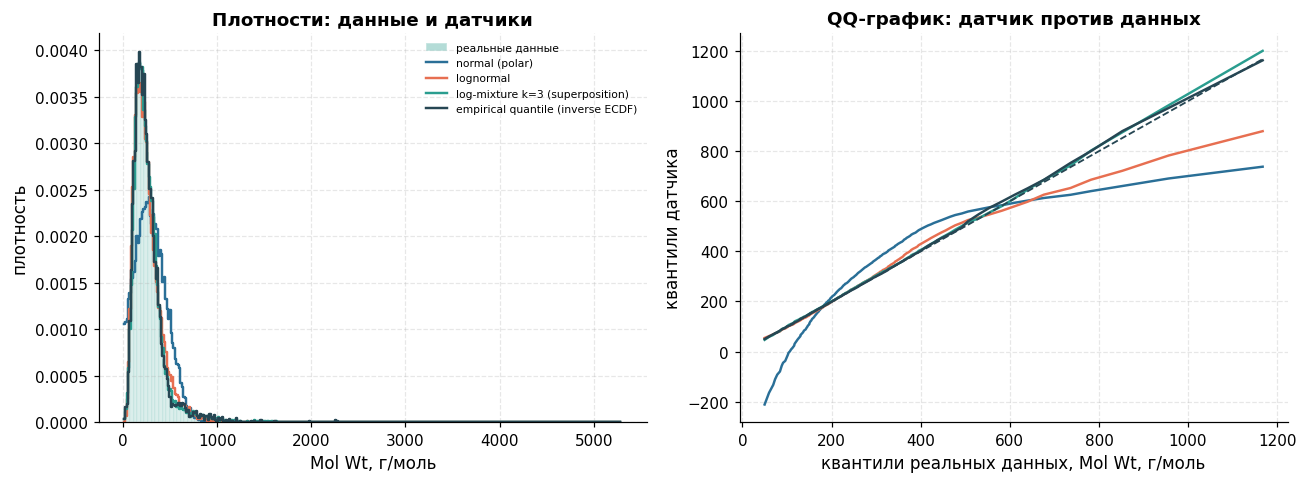

,KS D
lognormal (MLE),0.03201
смесь логнормальных k=3,0.009317
критическое D (5 %),0.01359


In [ ]:
_, samples3, info3 = run_rv("MolWt", x3, n=N_GEN, seed=SEED, k_mix=K3)
display(report.generator_table(x3, samples3))
display(report.match_verdict(x3, samples3))
report.plot_generator_comparison(x3, samples3, LAB3, C3)
g3 = info3["log_gmm"]
display(pd.DataFrame({"KS D": {
    "lognormal (MLE)": ks_fit(x3, "lognorm", fitted3["lognorm"]).statistic,
    f"смесь логнормальных k={K3}": stats.kstest(x3, lambda v: mixture.mixture_cdf(g3)(np.log(v))).statistic,
    "критическое D (5 %)": ks_crit(len(x3))}}))

> ✍️ **ЗАПОЛНИ САМА** (своими словами, потом удали эту подсказку)
>
> Интерпретация: чем смесь лучше одной логнормальной (тяжёлый правый хвост), что осталось несовпавшим (эксцесс), как это связано с реальными классами соединений (осторожно: без выдумывания смысла компонент).

<a id="r3-res"></a>

### 9.5 resume

[↑ к оглавлению](#toc)

> ✍️ **ЗАПОЛНИ САМА** (своими словами, потом удали эту подсказку)
>
> Итог по random 03.

<a id="s2-resume"></a>

## 10. Lab resume

[↑ к оглавлению](#toc)

In [ ]:
print(report.run_pytest())

62 passed in 11.99s  (код возврата 0)


> ✍️ **ЗАПОЛНИ САМА** (своими словами, потом удали эту подсказку)
>
> Общий вывод по спринту 2: какие алгоритмы реализованы, на каких величинах; где одиночные семейства из спринта 1 не прошли критерий согласия и как это исправила суперпозиция; что показали автотесты; что можно улучшить. Укажи, как вёлся git (смысловые коммиты).

<a id="s2-mark-table"></a>

### 10.1 cat_mark_table

[↑ к оглавлению](#toc)

> ✍️ Заполни `cat_id` и `coeff` по таблице категорий преподавателя; в `comment` укажи, что сделано. Критерии, которые считаешь выполненными, перечисли именно здесь.

| cat_id | notebook_link | coeff | comment |
|--------|---------------|-------|---------|
|  | [6](#base) | | Базовые датчики: ЛКГ (условия Халла–Добелла), Вихрь Мерсенна (MT19937), тесты Кнута |
|  | [6](#base) | | Нормальные датчики: полярный (Марсалья), метод отношений (Киндерман–Монахан), Бокс–Мюллер; сравнение эффективности |
|  | [7.3](#r1-code) | | Метод суперпозиции (смесь нормальных, EM) |
|  | [7.3](#r1-code) | | Квантильное преобразование (обратная функция эмпирической ф.р.) |
|  | [8.3](#r2-code) | | Метод Неймана (гамма Марсальи–Цанга) и композиция для Student t |
|  | [7.4](#r1-tests), [8.4](#r2-tests), [9.4](#r3-tests) | | Проверка совпадения метрик реальных данных и генератора, таблицы метрик, KS, QQ |
|  | [7](#r1), [8](#r2), [9](#r3) | | Три распределения (+ за каждое): skew-normal/смесь, Student t, логнормальное/смесь |
|  | [10](#s2-resume) | | Автотесты генератора (`pytest`, фиксированный seed) |
|  | `src/lab01/generators/continuous.py` | | Дополнительные алгоритмы: обратная функция (logistic, Weibull, Gumbel, экспоненциальное), показательный датчик без логарифмов (фон Нейман), Johnson SU |
|  | [11](#s2-refs) | | Список литературы |
|  | | | Версионирование: история git по смысловым шагам |

<a id="s2-refs"></a>

## 11. Список литературы

[↑ к оглавлению](#toc)

> ✍️ **ЗАПОЛНИ САМА** (своими словами, потом удали эту подсказку)
>
> Оформи по ГОСТ или единообразно, ссылайся на источники по тексту. Номера глав Кнута и Лагутина проверь по своим изданиям. Добавь книги и статьи из библиотек и баз (РГБ, РНБ, ИТМО, IEEE и т.д.): за подбор литературы есть балл.

1. Sorkun M. C., Khetan A., Er S. AqSolDB, a curated reference set of aqueous solubility and 2D descriptors for a diverse set of compounds // Scientific Data. 2019. Vol. 6. Art. 143. doi:10.1038/s41597-019-0151-1.
2. Кнут Д. Искусство программирования. Т. 2. Получисленные алгоритмы. Гл. 3: Случайные числа (3.2 — линейные конгруэнтные датчики, 3.3 — статистические тесты, 3.4.1 — числовые распределения).
3. Лагутин М. Б. Наглядная математическая статистика. ✍️ уточнить издание и главу.
4. Hull T. E., Dobell A. R. Random number generators // SIAM Review. 1962. Vol. 4, No. 3. P. 230–254.
5. Matsumoto M., Nishimura T. Mersenne Twister: a 623-dimensionally equidistributed uniform pseudo-random number generator // ACM TOMACS. 1998. Vol. 8, No. 1. P. 3–30.
6. Marsaglia G., Bray T. A. A convenient method for generating normal variables // SIAM Review. 1964. Vol. 6, No. 3. P. 260–264.
7. Kinderman A. J., Monahan J. F. Computer generation of random variables using the ratio of uniform deviates // ACM TOMS. 1977. Vol. 3, No. 3. P. 257–260.
8. Marsaglia G., Tsang W. W. A simple method for generating gamma variables // ACM TOMS. 2000. Vol. 26, No. 3. P. 363–372.
9. Azzalini A. A class of distributions which includes the normal ones // Scandinavian Journal of Statistics. 1985. Vol. 12, No. 2. P. 171–178.
10. Dempster A. P., Laird N. M., Rubin D. B. Maximum likelihood from incomplete data via the EM algorithm // J. Royal Statistical Society B. 1977. Vol. 39, No. 1. P. 1–38.
11. von Neumann J. Various techniques used in connection with random digits // Nat. Bur. Standards Appl. Math. Ser. 1951. Vol. 12. P. 36–38.
12. ✍️ …